# Rings of plasmonic rods: a magnetic metamolecule

Notebooks 02 and 03 found a permeability in a lattice of rods of large positive permittivity: each rod carries a loop of displacement current. A different route to magnetism at optical frequencies, proposed without split rings, is a ring of plasmonic nanoparticles (A. Alù, A. Salandrino and N. Engheta, Opt. Express 14, 1557 (2006); A. Alù and N. Engheta, Phys. Rev. B 78, 085112 (2008)). Each particle has an electric dipole resonance, and the mode in which the dipoles of a ring circulate carries a magnetic moment. Here the particles are rods and the ring is four Drude rods around the center of each square cell, so the lattice keeps the $C_{4v}$ symmetry of notebooks 02 to 04 and the coefficients $\tau$, $\delta$, $\lambda$ of notebook 01 apply unchanged. The notebook asks of this structure what notebooks 03 and 06 asked of dielectric and metal rods: does the circulating mode give a resonant $\tau$ and a negative $\mu$, is that $\mu$ a permeability in the Landau-Lifshitz sense, and what do loss and size do to it.

## What this notebook shows

- The isolated ring, from the T-matrix of the cluster of four rods (TE): its magnetic-dipole coefficient has a resonance below the electric ones; the cluster solution at that resonance has four equal tangential dipoles, and a coupled-dipole model built from the single-rod Mie coefficient locates the resonance to about one percent.
- The lattice of rings: Bloch modes and the source-driven $\varepsilon(\omega,\mathbf k)$ of the same structure, which agree where they must; the second-order coefficients through the resonance; a band of negative $\mu$ without loss, and how narrow it is.
- Whether $\mu$ is a permeability: the Landau-Lifshitz ratio of the resonant part of $\tau$ to the other second-order terms, the anisotropy of the apparent permeability, and how far the local model $k=k_0\sqrt{\varepsilon_T\mu}$ reaches against the exact Bloch wavenumber.
- Loss and size: bulk-silver loss and ten times that, the loss below which the negative band survives, and what happens to the resonance and its strength when the whole structure is made electrically larger.

## Conventions

As in the other notebooks: $e^{-i\omega t}$, $\varepsilon_0=\mu_0=c=1$, lengths in units of the period $a$, $f=a/\lambda_0=k_0/2\pi$ (always a frequency), TE means $\mathbf H$ along the rods. The rods are Drude, $\varepsilon_m=1-f_p^2/[f(f+if_\gamma)]$, with $f_p=a/\lambda_p$ the plasma frequency and $f_\gamma$ the collision frequency in the same units (collisionless first, then $f_\gamma/f_p=1/300$, a bulk loss of silver within the range of published Drude fits, about 1/440 to 1/190 (checked 2026-11-23), and $1/30$; the physical sizes and size-dependent damping are discussed under the caveats). Four rods of radius $r$ sit at $(\pm s,0)$ and $(0,\pm s)$ in each cell. $\varepsilon_T(\omega,0)$ is the transverse permittivity at $\mathbf k=0$, and $\tau$, $\delta$, $\lambda$ are the second-order coefficients of notebook 01, section 3 (transverse $\tau-\delta\cos4\varphi$, longitudinal $\lambda+\delta\cos4\varphi$), obtained as in notebook 03 by Cauchy integrals on a circle of complex $\kappa$ along $\Gamma X$ ($\varphi=0$) and $\Gamma M$ ($\varphi=\pi/4$). The permeability is $\mu_{zz}=1/(1-k_0^2\tau)$, and the apparent permeabilities along the two directions are $\mu_X=1/[1-k_0^2(\tau-\delta)]$ and $\mu_M=1/[1-k_0^2(\tau+\delta)]$. $f_m$ is the frequency at which $\tau$ has its pole (so $\mu=0$ there) and $f_P$ the frequency at which $\mu$ has its pole.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/spatial_dispersion (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # basislattice.py and rodlattice.py sit next to this notebook
import basislattice as bl
import rodlattice as rl
from scipy.special import jv, jvp, yv, yvp, iv, ivp, hankel1, j1
from scipy.optimize import brentq, minimize_scalar

TWO_PI = 2 * np.pi
T0 = time.perf_counter()
S_RING, R_ROD, FP = 0.22, 0.08, 0.2      # ring radius, rod radius, plasma frequency a/lambda_p of the base structure

## 0. Setup: the structure, and one repair

The structure is the suggested start: $s=0.22$, $r=0.08$, $f_p=0.2$. The rods are thin ($r$ is a third of $s$), the particles are deep subwavelength ($a/\lambda_p=0.2$), and the gap between neighboring rods of a ring (printed) is about twice a rod radius. The values were kept after a small exploration, tabulated at the end of section 4: moderate changes of $s$ and $r$ change the residue $A$ of the magnetic resonance by less than a factor of two and the relative width of the negative band by less than a factor of three, and for a larger ring (radius 0.30) the lattice 'pole' sits where $\varepsilon_T$ is large and negative (printed). A thin metal rod has its electric dipole resonance at $\varepsilon_m=-1$, that is $f=f_p/\sqrt2$.

**A repair.** `rodlattice.mie_pq`, which the Hermitian mode condition of `basislattice` calls, evaluates `np.sqrt(eps * mu)` of a real negative number and returns NaN, so Bloch modes of rods with negative permittivity cannot be found. The first cell below shows this and installs a replacement in the running kernel (the files are not edited). For $\varepsilon\mu<0$ the wave number inside is $i\kappa$, $J_l(ix)=i^lI_l(x)$, and the common factor $i^l$ drops out of $t_l=-p_l/(p_l+iq_l)$. The replacement is checked against the Mie coefficients `rl.mie_t`, which use complex arithmetic and are not affected, and it returns the original values for $\varepsilon>0$. The multiple-scattering and driven calculations do not use `mie_pq`.

In [3]:
def eps_drude(f, fp=FP, fg=0.0):
    """Drude permittivity 1 - fp^2 / (f (f + i fg)); real (float) when there is no loss."""
    e = 1 - fp**2 / (f * (f + 1j * fg))
    return float(e.real) if fg == 0 else complex(e)


def ring(eps, s=S_RING, r=R_ROD):
    """Four identical rods at (+-s, 0) and (0, +-s) about the origin."""
    return [bl.Rod(c, r, eps) for c in ((s, 0.0), (0.0, s), (-s, 0.0), (0.0, -s))]


gap = bl.check_rods(ring(-3.0))
print(f"ring radius s = {S_RING}, rod radius r = {R_ROD}, Drude f_p = {FP}; filling fraction of the metal {4 * np.pi * R_ROD**2:.4f}")
print(f"smallest gap between rod surfaces, images in neighboring cells included: {gap:.4f} a")
print(f"neighboring rods in the ring: centers {np.sqrt(2) * S_RING:.4f} apart; ring to the next ring (rod to rod, along an axis): {1 - 2 * S_RING - 2 * R_ROD:.4f}")
print(f"single thin rod, electric dipole resonance at eps_m = -1: f = f_p / sqrt(2) = {FP / np.sqrt(2):.5f}")
assert gap > 0.1

# --- the repair: rodlattice.mie_pq takes np.sqrt(eps * mu) of a negative float and returns NaN
_mie_pq_orig = rl.mie_pq


def mie_pq_signed(l, k0, R, eps, pol="TM", mu=1.0):
    """rodlattice.mie_pq, extended to eps * mu < 0 (imaginary k1 = i kappa).

    With J_l(i x) = i^l I_l(x) the common factor i^l drops out of t_l = -p_l / (p_l + i q_l), and the real
    p_l, q_l below have the same ratio q_l / p_l and the same moduli up to that unit factor."""
    if eps * mu > 0:
        return _mie_pq_orig(l, k0, R, eps, pol, mu)
    l = np.abs(np.asarray(l))
    kap = k0 * np.sqrt(-eps * mu)
    q1 = 1.0 / mu if pol == "TM" else 1.0 / eps
    x0, x1 = k0 * R, kap * R
    p = q1 * kap * ivp(l, x1) * jv(l, x0) - k0 * iv(l, x1) * jvp(l, x0)
    q = q1 * kap * ivp(l, x1) * yv(l, x0) - k0 * iv(l, x1) * yvp(l, x0)
    return p, q


with np.errstate(all="ignore"):
    broken = _mie_pq_orig(np.arange(3), TWO_PI * 0.12, R_ROD, -1.7778, "TE")
print("rodlattice.mie_pq at eps = -1.78 (before the repair):", [np.round(x, 3) for x in broken])
rl.mie_pq = mie_pq_signed
l5 = np.arange(0, 5)
worst = 0.0
for f in (0.08, 0.12, 0.14):
    e = eps_drude(f)
    p, q = rl.mie_pq(l5, TWO_PI * f, R_ROD, e, "TE")
    worst = max(worst, np.abs(-p / (p + 1j * q) - rl.mie_t(l5, TWO_PI * f, R_ROD, e, "TE")).max())
check("repaired p, q reproduce the Mie coefficients t_l = -p/(p + iq) of rl.mie_t, eps < 0 (all orders 0..4, three frequencies)", worst, 1e-11)
same = rl.mie_pq(l5, 1.3, R_ROD, 4.0, "TE")
assert all(np.array_equal(a, b) for a, b in zip(same, _mie_pq_orig(l5, 1.3, R_ROD, 4.0, "TE"))), "positive eps must be untouched"
print("for eps > 0 the repaired function returns the original values unchanged")

ring radius s = 0.22, rod radius r = 0.08, Drude f_p = 0.2; filling fraction of the metal 0.0804
smallest gap between rod surfaces, images in neighboring cells included: 0.1511 a
neighboring rods in the ring: centers 0.3111 apart; ring to the next ring (rod to rod, along an axis): 0.4000
single thin rod, electric dipole resonance at eps_m = -1: f = f_p / sqrt(2) = 0.14142
rodlattice.mie_pq at eps = -1.78 (before the repair): [array([nan, nan, nan]), array([nan, nan, nan])]
PASS  repaired p, q reproduce the Mie coefficients t_l = -p/(p + iq) of rl.mie_t, eps < 0 (all orders 0..4, three frequencies): got 2.84251e-15, target 0, |diff| 2.84e-15 <= 1e-11
for eps > 0 the repaired function returns the original values unchanged


## 1. The isolated ring

`basislattice.molecule_t_matrix` gives the T-matrix of the cluster about its center: an incident regular field $\sum_{m'}a_{m'}J_{m'}(k_0r)e^{im'\varphi}$ produces the scattered field $\sum_mB_mH_m(k_0r)e^{im\varphi}$ with $B=Ta$. For $H_z$ the $m=0$ entry is the response of the cluster to a uniform magnetic field, that is a magnetic dipole; $m=\pm1$ is an electric dipole and $m=\pm2$ a quadrupole. For a cluster with $C_{4v}$ symmetry, orders $m$ and $m'$ can couple only if $m-m'$ is a multiple of 4, and for a lossless cluster $S=I+2T$ is unitary. The next cell scans $|T_{00}|$, $|T_{11}|$, $|T_{22}|$ against frequency and locates the peaks of the first two.

In [4]:
M_MOL, L_MOL = 4, 8


def tmat(f, M=M_MOL, L=L_MOL, eps=None):
    """TE T-matrix of the collisionless ring about its center at frequency f; T[L + m, L + m'], m, m' = -L..L."""
    e = eps_drude(f) if eps is None else eps
    return bl.molecule_t_matrix(TWO_PI * f, ring(e), "TE", M=M, Lmol=L)


def refine_peak(fun, f0, half=2e-4):
    """Local maximum of fun near f0 by bounded scalar minimization."""
    r_ = minimize_scalar(lambda x: -fun(x), bounds=(f0 - half, f0 + half), method="bounded", options=dict(xatol=1e-13))
    return r_.x, -r_.fun


def local_maxima(F, v, thr):
    return [i for i in range(1, len(F) - 1) if v[i] > v[i - 1] and v[i] >= v[i + 1] and v[i] > thr]


F_SCAN = np.linspace(0.04, 0.19, 6001)
t0 = time.perf_counter()
TS = np.array([[abs(T[L_MOL, L_MOL]), abs(T[L_MOL + 1, L_MOL + 1]), abs(T[L_MOL + 2, L_MOL + 2]), abs(T[L_MOL + 4, L_MOL + 4])]
               for T in (tmat(f) for f in F_SCAN)])
print(f"T-matrix at {len(F_SCAN)} frequencies: {time.perf_counter() - t0:.1f} s")

# the magnetic resonance: the strongest m = 0 peak; the electric ones: the peaks of m = +-1
i0 = local_maxima(F_SCAN, TS[:, 0], 0.2)
f_mag_iso, t00_peak = max((refine_peak(lambda x: abs(tmat(x)[L_MOL, L_MOL]), F_SCAN[i]) for i in i0), key=lambda x: x[1])
i1 = local_maxima(F_SCAN, TS[:, 1], 0.5)
peaks_e = sorted(refine_peak(lambda x: abs(tmat(x)[L_MOL + 1, L_MOL + 1]), F_SCAN[i], 5e-5) for i in i1)
print(f"magnetic resonance (peak of |T_00|) of the isolated ring: f = {f_mag_iso:.6f}, |T_00| = {t00_peak:.7f}")
print("peaks of |T_11| above 0.5 (electric resonances):  " + ",  ".join(f"{f:.5f} ({v:.3f})" for f, v in peaks_e))
print(f"all peaks of |T_00| above 0.2: " + ",  ".join(f"{F_SCAN[i]:.5f} ({TS[i, 0]:.3f})" for i in i0))
print(f"the single-rod electric resonance f_p/sqrt(2) = {FP / np.sqrt(2):.5f}")
check("at the magnetic resonance |T_00| reaches the unitarity limit 1 (lossless, one open channel)", t00_peak, 2e-3, 1.0)
assert f_mag_iso < peaks_e[0][0] < FP / np.sqrt(2) + 0.01 and f_mag_iso < FP / np.sqrt(2)

T-matrix at 6001 frequencies: 4.0 s
magnetic resonance (peak of |T_00|) of the isolated ring: f = 0.127701, |T_00| = 0.9999995
peaks of |T_11| above 0.5 (electric resonances):  0.13662 (1.000),  0.13924 (1.000),  0.14126 (1.000),  0.14137 (1.000),  0.14142 (1.000),  0.14148 (1.000),  0.14297 (1.000),  0.14527 (1.000)
all peaks of |T_00| above 0.2: 0.12770 (0.999)
the single-rod electric resonance f_p/sqrt(2) = 0.14142
PASS  at the magnetic resonance |T_00| reaches the unitarity limit 1 (lossless, one open channel): got 0.999999, target 1, |diff| 5.28e-07 <= 2e-03


The $m=0$ coefficient has a single peak above 0.2, below every electric peak and below the single-rod resonance $f_p/\sqrt2$ (printed). Its height is the unitarity limit: a lossless cluster with one open channel can only respond with $S_{00}=-1$ at resonance, $|T_{00}|=1$. The $m=\pm1$ coefficient has a family of peaks (the printed list) around $f_p/\sqrt2$; that they accumulate near the frequency at which a single rod has $\varepsilon_m=-1$ suggests, but the notebook does not show, that they are collective modes built from the higher multipoles of the rods, which all resonate near $\varepsilon_m=-1$ in the quasi-static limit. The next cell checks the selection rule and unitarity, and that the resonances do not move when the multipole basis is enlarged.

(a) selection rule and unitarity of the cluster T-matrix
    f = 0.09: max |T| = 0.0109, largest forbidden element / max = 1.8e-13, |S^H S - 1| = 4.2e-15
    f = 0.12: max |T| = 0.0434, largest forbidden element / max = 1.4e-13, |S^H S - 1| = 1.3e-14
    f = 0.1277: max |T| = 0.9998, largest forbidden element / max = 5.1e-13, |S^H S - 1| = 4.0e-11
    f = 0.1365: max |T| = 0.9481, largest forbidden element / max = 1.2e-12, |S^H S - 1| = 2.9e-12
PASS  orders m and m' couple only if m - m' is a multiple of 4 (largest forbidden element over the largest element; the resonance amplifies rounding): got 1.19099e-12, target 0, |diff| 1.19e-12 <= 1e-10
PASS  S = I + 2T is unitary for the lossless ring (Lmol = 18, M = 8, largest element of S^H S - 1): got 3.95521e-11, target 0, |diff| 3.96e-11 <= 1e-09
    magnetic resonance with M = 6, Lmol = 12: 0.1276997 (M = 4, Lmol = 8: 0.1277006)
PASS  magnetic resonance of the ring, M = 4 against M = 6 (relative): got -7.14593e-06, target 0, |diff| 7.15e-

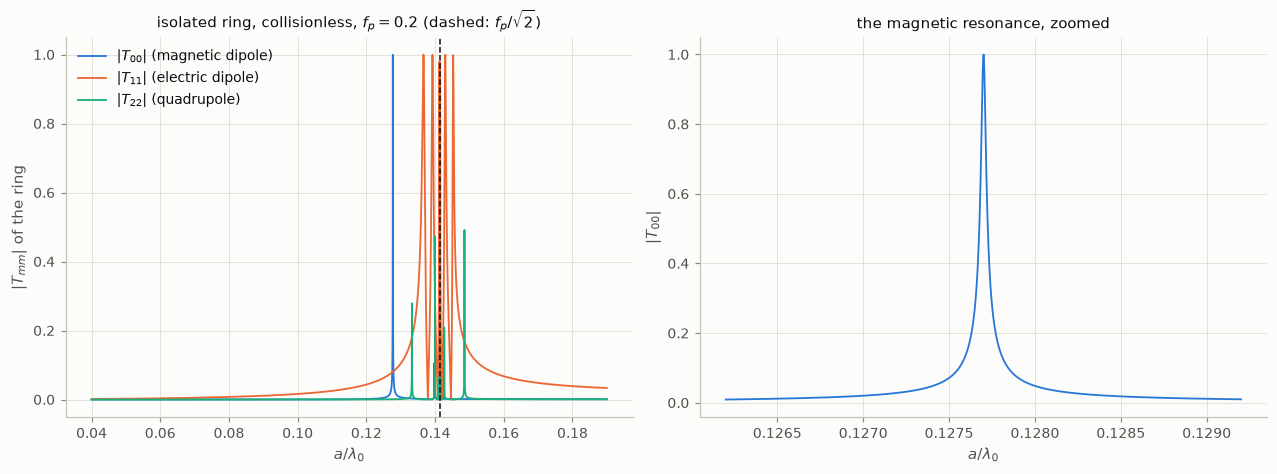

In [5]:
print("(a) selection rule and unitarity of the cluster T-matrix")
Lc, Mc = 18, 8
f_test = [0.09, 0.12, 0.1277, 0.1365]
worst_sel, worst_uni = 0.0, 0.0
for f in f_test:
    T = tmat(f, Mc, Lc)
    m = np.arange(-Lc, Lc + 1)
    forbidden = ((m[:, None] - m[None, :]) % 4) != 0
    worst_sel = max(worst_sel, np.abs(T[forbidden]).max() / np.abs(T).max())
    S = np.eye(2 * Lc + 1) + 2 * T
    worst_uni = max(worst_uni, np.abs(S.conj().T @ S - np.eye(2 * Lc + 1)).max())
    print(f"    f = {f}: max |T| = {np.abs(T).max():.4f}, largest forbidden element / max = {np.abs(T[forbidden]).max() / np.abs(T).max():.1e}, |S^H S - 1| = {np.abs(S.conj().T @ S - np.eye(2 * Lc + 1)).max():.1e}")
check("orders m and m' couple only if m - m' is a multiple of 4 (largest forbidden element over the largest element; the resonance amplifies rounding)", worst_sel, 1e-10)
check("S = I + 2T is unitary for the lossless ring (Lmol = 18, M = 8, largest element of S^H S - 1)", worst_uni, 1e-9)

# truncation: the resonance frequencies against a larger basis
f_big, v_big = refine_peak(lambda x: abs(tmat(x, 6, 12)[12, 12]), f_mag_iso, 2e-5)
print(f"    magnetic resonance with M = 6, Lmol = 12: {f_big:.7f} (M = 4, Lmol = 8: {f_mag_iso:.7f})")
check("magnetic resonance of the ring, M = 4 against M = 6 (relative)", f_big / f_mag_iso - 1, 1e-4)
e_big = sorted(refine_peak(lambda x: abs(tmat(x, 6, 12)[12 + 1, 12 + 1]), f, 2e-5)[0] for f, _ in peaks_e[:2])
print(f"    lowest two electric resonances with M = 6: {e_big[0]:.6f}, {e_big[1]:.6f}")
check("lowest electric resonance of the ring, M = 4 against M = 6 (relative)", e_big[0] / peaks_e[0][0] - 1, 1e-4)

# the figure
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.2))
for ax, (lo, hi) in zip(axs, ((0.04, 0.19), (0.1262, 0.1292))):
    sel = (F_SCAN >= lo) & (F_SCAN <= hi)
    for j, (lab, c) in enumerate(((r"$|T_{00}|$ (magnetic dipole)", CAT[0]), (r"$|T_{11}|$ (electric dipole)", CAT[1]), (r"$|T_{22}|$ (quadrupole)", CAT[2]))):
        ax.plot(F_SCAN[sel], TS[sel, j], color=c, label=lab, lw=1.2)
    ax.axvline(FP / np.sqrt(2), color=INK, ls="--", lw=1)
    ax.set(xlabel=r"$a/\lambda_0$", ylabel=r"$|T_{mm}|$ of the ring")
axs[0].legend(loc="upper left")
axs[0].set_title(r"isolated ring, collisionless, $f_p=0.2$ (dashed: $f_p/\sqrt{2}$)")
fz = np.linspace(0.1262, 0.1292, 1500)
axs[1].clear()
axs[1].plot(fz, [abs(tmat(f)[L_MOL, L_MOL]) for f in fz], color=CAT[0], lw=1.2)
axs[1].set(xlabel=r"$a/\lambda_0$", ylabel=r"$|T_{00}|$", title="the magnetic resonance, zoomed")
plt.show()

**The mode.** The next cell solves the cluster for an incident uniform magnetic field ($m=0$ only) at the resonance and builds the field. It keeps the rod coefficients (the same equations as `molecule_t_matrix`, whose far-field coefficients it must reproduce). As a check that does not share the translation formulas, it evaluates the field on the two sides of the rod surfaces with every rod's field written about its own center and tests the continuity of $H_z$ and of $\varepsilon^{-1}\partial_nH_z$. It also reads the electric dipole moment of each rod from its $m=\pm1$ coefficients, $H_z=\frac{k_0^2}{4}H_1(k_0r)(p_x\sin\varphi-p_y\cos\varphi)$ for a line dipole (derived below). The figure shows the real field at the instant when $H_z$ at the center is largest; finite differences across a rod surface are wrong, so a band of three pixels around each surface is masked before $\mathbf E=(i/k_0\varepsilon)(\partial_yH_z,-\partial_xH_z)$ is formed.

In [6]:
def cluster_solve(k0, rods, a0, M=6):
    """Outgoing coefficients b[j, l] (l = -M..M) of every rod of the cluster for the incident regular field
    sum_m a0[m] J_m(k0 r) exp(i m phi) about the origin (a0 indexed m = -L..L), and the regular coefficients a[j, l]
    incident on each rod (the incident wave and the other rods). Same ingredients as molecule_t_matrix."""
    N, nl, L = len(rods), 2 * M + 1, (len(a0) - 1) // 2
    ls = np.arange(-M, M + 1)
    t = np.array([rl.mie_t(ls, k0, r.radius, r.eps, "TE", r.mu) for r in rods])
    big = np.eye(N * nl, dtype=complex)
    rhs = np.zeros(N * nl, complex)
    inc = np.zeros((N, nl), complex)
    for i, ri in enumerate(rods):
        si = slice(i * nl, (i + 1) * nl)
        inc[i] = bl.regular_translation(k0, ri.d, L, M) @ a0
        rhs[si] = t[i] * inc[i]
        for j, rj in enumerate(rods):
            if i != j:
                big[si, j * nl:(j + 1) * nl] -= t[i][:, None] * bl.outgoing_to_regular(k0, rj.d - ri.d, M)
    b = np.linalg.solve(big, rhs).reshape(N, nl)
    a = inc.copy()
    for i, ri in enumerate(rods):
        for j, rj in enumerate(rods):
            if i != j:
                a[i] += bl.outgoing_to_regular(k0, rj.d - ri.d, M) @ b[j]
    return b, a


def hz_field(k0, rods, b, a, a0, X, Y, M=6):
    """H_z on the grid (X, Y) from the cluster solution; inside rod j the interior field built from the same coefficients."""
    L = (len(a0) - 1) // 2
    ls, ms = np.arange(-M, M + 1), np.arange(-L, L + 1)
    rho, ph = np.hypot(X, Y), np.arctan2(Y, X)
    H = np.zeros(X.shape, complex)
    for m_, a_ in zip(ms, a0):
        if a_ != 0:
            H += a_ * jv(m_, k0 * rho) * np.exp(1j * m_ * ph)
    inside = []
    for j, rd in enumerate(rods):
        dx, dy = X - rd.d[0], Y - rd.d[1]
        rj, pj = np.hypot(dx, dy), np.arctan2(dy, dx)
        rs = np.maximum(rj, rd.radius)
        for l_, bl_ in zip(ls, b[j]):
            H += bl_ * hankel1(l_, k0 * rs) * np.exp(1j * l_ * pj)
        inside.append(rj < rd.radius)
    for j, rd in enumerate(rods):
        dx, dy = X - rd.d[0], Y - rd.d[1]
        rj, pj = np.hypot(dx, dy), np.arctan2(dy, dx)
        k1 = k0 * np.sqrt(complex(rd.eps))
        x0, x1 = k0 * rd.radius, k1 * rd.radius
        Hin = np.zeros(X.shape, complex)
        for l_ in ls:
            c = (a[j, l_ + M] * jv(l_, x0) + b[j, l_ + M] * hankel1(l_, x0)) / jv(l_, x1)
            Hin += c * jv(l_, k1 * rj) * np.exp(1j * l_ * pj)
        H = np.where(inside[j], Hin, H)
    return H, inside


def dipole_moments(k0, b):
    """Electric dipole moment (per unit length) of every rod from b_{+-1}: H_z = (k0^2/4) H_1(k0 r) (p_x sin(phi) - p_y cos(phi))."""
    M = (b.shape[1] - 1) // 2
    b1, bm1 = b[:, 1 + M], b[:, -1 + M]
    return (4 / k0**2) * np.stack([1j * (b1 + bm1), -(b1 - bm1)], axis=1)


# a regular incident wave with m = 0 only (nearly uniform H_z over the ring)
Lc, Mc = 10, 8
a0_mag = np.zeros(2 * Lc + 1, complex); a0_mag[Lc] = 1.0
k0m = TWO_PI * f_mag_iso
rods_m = ring(eps_drude(f_mag_iso))
b_m, a_m = cluster_solve(k0m, rods_m, a0_mag, Mc)

print("(b) the cluster solution against the T-matrix, and against the boundary conditions evaluated with all fields written about their own centers")
B_far = sum(bl.outgoing_translation(k0m, r.d, Lc, Mc) @ b_m[j] for j, r in enumerate(rods_m))
T_m = bl.molecule_t_matrix(k0m, rods_m, "TE", M=Mc, Lmol=Lc)
check("far-field coefficients from the rod solution, against T a0 of molecule_t_matrix (relative)", np.abs(B_far - T_m @ a0_mag).max() / np.abs(B_far).max(), 1e-10)
# continuity of H_z and of (1/eps) dH_z/dn across each rod surface; outside written with the plain rod fields about their centers
eps_m = rods_m[0].eps
jump_h, jump_q, scale_h, scale_q = 0.0, 0.0, 0.0, 0.0
for j, rd in enumerate(rods_m):
    for ang in (0.3, 1.9, 3.4, 5.1):
        n_ = np.array([np.cos(ang), np.sin(ang)])
        p0 = rd.d + rd.radius * n_
        h = 1e-8
        pts = np.array([p0 + (-h) * n_, p0 + h * n_, p0 + 2 * h * n_, p0 - 2 * h * n_])
        Hv, ins = hz_field(k0m, rods_m, b_m, a_m, a0_mag, pts[:, 0:1], pts[:, 1:2], Mc)
        Hv = Hv[:, 0]
        assert ins[j][0, 0] and not ins[j][1, 0]
        d_in = (Hv[0] - Hv[3]) / h                        # inside, toward the surface: points at -h and -2h
        d_out = (Hv[2] - Hv[1]) / h
        jump_h, scale_h = max(jump_h, abs(Hv[0] - Hv[1])), max(scale_h, abs(Hv[1]))
        jump_q, scale_q = max(jump_q, abs(d_out - d_in / eps_m)), max(scale_q, abs(d_out))
worst_h, worst_q = jump_h / scale_h, jump_q / scale_q
print(f"    H_z across the surface (points 1e-8 apart), jump over the largest |H_z| on the surfaces {worst_h:.1e}; (1/eps) dH/dn jump over the largest |dH/dn| {worst_q:.1e}")
check("H_z continuous across the rod surfaces (largest jump over the largest value, M = 8)", worst_h, 1e-4)
check("(1/eps) dH_z/dn continuous across the rod surfaces (largest jump over the largest value, one-sided differences)", worst_q, 1e-3)

dp = dipole_moments(k0m, b_m)
ph_hat = np.array([[-r.d[1], r.d[0]] for r in rods_m]) / S_RING
r_hat = np.array([r.d for r in rods_m]) / S_RING
p_tan = (dp * ph_hat).sum(1)
p_rad = (dp * r_hat).sum(1)
print(f"(c) the dipole moments of the four rods at the magnetic resonance (incident m = 0 wave): tangential {np.round(p_tan, 4)}, radial {np.round(np.abs(p_rad), 12)}")
check("the excited mode is the circulating one: radial dipole component over tangential (largest)", np.abs(p_rad).max() / np.abs(p_tan).min(), 1e-10)
assert np.abs(p_tan - p_tan[0]).max() < 1e-9 * abs(p_tan[0]), "all four tangential dipoles equal"
print(f"    |p_tangential| = {abs(p_tan[0]):.4f} per rod in a unit incident field; magnetic-dipole coefficient T_00 = {T_m[Lc, Lc]:.5f}")

(b) the cluster solution against the T-matrix, and against the boundary conditions evaluated with all fields written about their own centers
PASS  far-field coefficients from the rod solution, against T a0 of molecule_t_matrix (relative): got 7.80133e-16, target 0, |diff| 7.80e-16 <= 1e-10
    H_z across the surface (points 1e-8 apart), jump over the largest |H_z| on the surfaces 2.2e-06; (1/eps) dH/dn jump over the largest |dH/dn| 3.7e-05
PASS  H_z continuous across the rod surfaces (largest jump over the largest value, M = 8): got 2.24367e-06, target 0, |diff| 2.24e-06 <= 1e-04
PASS  (1/eps) dH_z/dn continuous across the rod surfaces (largest jump over the largest value, one-sided differences): got 3.72439e-05, target 0, |diff| 3.72e-05 <= 1e-03
(c) the dipole moments of the four rods at the magnetic resonance (incident m = 0 wave): tangential [-17.5966-1.1175j -17.5966-1.1175j -17.5966-1.1175j -17.5966-1.1175j], radial [2.e-12 2.e-12 2.e-12 2.e-12]
PASS  the excited mode is the circ

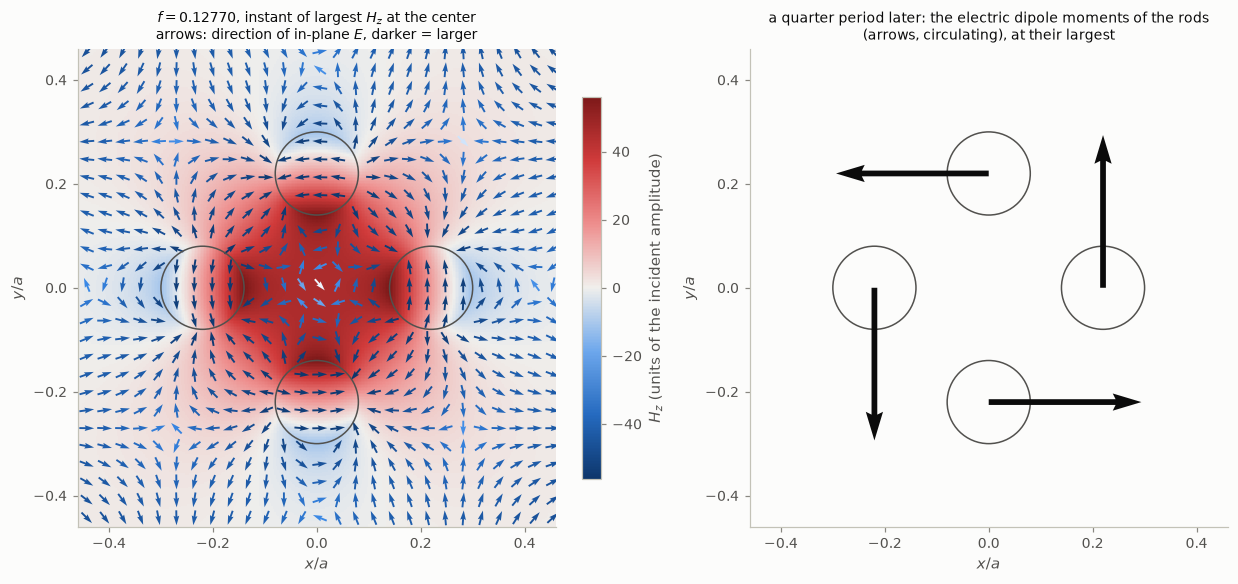

snapshot instant: phase theta = -1.634 rad; largest |H_z| in the plot 56.1, at the ring center 45.40; incident amplitude 1
phase between the dipole moment and H_z at the center: -90.0 degrees; H_z at the center at the instant of largest dipole moment: -0.00
largest |H_z| in the plot at the instant of largest dipole moments, over the largest at the first instant: 0.000
pixels masked around the rod surfaces: 4200 of 103041


In [7]:
# the field of the magnetic mode at one instant: H_z in color, in-plane E as arrows, a band around each rod surface masked for E
n_grid, half = 321, 0.46
xs = np.linspace(-half, half, n_grid)
XG, YG = np.meshgrid(xs, xs)
Hg, inside = hz_field(k0m, rods_m, b_m, a_m, a0_mag, XG, YG, Mc)
hstep = xs[1] - xs[0]
theta = -np.angle(Hg[n_grid // 2, n_grid // 2])                   # instant at which H_z at the ring center is largest
Hr = (Hg * np.exp(1j * theta)).real
dHdy, dHdx = np.gradient(Hg * np.exp(1j * theta), hstep)
eps_map = np.where(np.any(inside, axis=0), eps_m, 1.0)
Ex, Ey = ((1j / (k0m * eps_map)) * dHdy).real, ((1j / (k0m * eps_map)) * (-dHdx)).real
band = np.zeros_like(Hr, bool)
for rd in rods_m:
    band |= np.abs(np.hypot(XG - rd.d[0], YG - rd.d[1]) - rd.radius) < 3 * hstep
Ex, Ey = np.where(band, np.nan, Ex), np.where(band, np.nan, Ey)

fig, axs = plt.subplots(1, 2, figsize=(11.5, 5.2))
vmax = np.abs(Hr).max()
im = axs[0].imshow(Hr, extent=(-half, half, -half, half), cmap=DIV, vmin=-vmax, vmax=vmax)
step = 12
q_ = (slice(6, None, step), slice(6, None, step))
Em = np.hypot(Ex, Ey)
qv = axs[0].quiver(XG[q_], YG[q_], (Ex / Em)[q_], (Ey / Em)[q_], np.log10(Em[q_]), cmap="seq_blue", clim=(np.nanmin(np.log10(Em[q_])), np.nanmax(np.log10(Em[q_]))),
                   scale=32, width=0.004, pivot="mid")
fig.colorbar(im, ax=axs[0], label=r"$H_z$ (units of the incident amplitude)", shrink=0.8)
for ax in axs:
    for rd in rods_m:
        ax.add_patch(plt.Circle(rd.d, rd.radius, fill=False, ec=INK2, lw=1.0))
    ax.set(xlabel=r"$x/a$", ylabel=r"$y/a$", aspect="equal", xlim=(-half, half), ylim=(-half, half))
    ax.grid(False)
axs[0].set_title(rf"$f={f_mag_iso:.5f}$, instant of largest $H_z$ at the center" + "\n" + r"arrows: direction of in-plane $E$, darker = larger", fontsize=9)
theta2 = -np.angle(p_tan[0])                                       # a quarter period earlier or later: the dipoles are at their largest
Hr2 = (Hg * np.exp(1j * theta2)).real
pr = (dp * np.exp(1j * theta2)).real
axs[1].quiver([r.d[0] for r in rods_m], [r.d[1] for r in rods_m], pr[:, 0], pr[:, 1], color=INK, angles="xy", scale_units="xy", scale=60, width=0.012, zorder=5)
axs[1].set_title("a quarter period later: the electric dipole moments of the rods\n(arrows, circulating), at their largest", fontsize=9)
plt.show()
print(f"snapshot instant: phase theta = {theta:.3f} rad; largest |H_z| in the plot {np.abs(Hg).max():.1f}, at the ring center {abs(Hg[n_grid // 2, n_grid // 2]):.2f}; incident amplitude 1")
print(f"phase between the dipole moment and H_z at the center: {np.degrees(np.angle(Hg[n_grid // 2, n_grid // 2] / p_tan[0])):.1f} degrees; H_z at the center at the instant of largest dipole moment: {Hr2[n_grid // 2, n_grid // 2]:.2f}")
print(f"largest |H_z| in the plot at the instant of largest dipole moments, over the largest at the first instant: {np.abs(Hr2).max() / np.abs(Hr).max():.3f}")
print(f"pixels masked around the rod surfaces: {band.sum()} of {band.size}")

The figure and the printed numbers say that at the resonance the four rods carry equal tangential dipoles: the radial components vanish to rounding, which the symmetry of the incident field requires (an $m=0$ field is invariant under the whole point group and can excite only the circulating class), and the dipoles are a quarter period out of phase with $H_z$ at the center. $H_z$ is concentrated inside the ring (the figure) and the in-plane $E$ winds around the center.

**A coupled-dipole estimate.** Treat each rod as a point dipole in the field of the others. A line dipole $\mathbf p$ (per unit length) radiates $H_z=\frac{k_0^2}{4}H_1(k_0r)(p_x\sin\varphi-p_y\cos\varphi)$, from $(\nabla^2+k_0^2)H_z=-(\nabla\times\mathbf J)_z$ with $\mathbf J=-i\omega\mathbf p\,\delta$, and the field it produces at displacement $\mathbf r$ is $\mathbf E=G(\mathbf r)\mathbf p$ with $G=\frac i4(k_0^2+\nabla\nabla)H_0(k_0r)$. Comparing the $m=\pm1$ terms with $H_z=\sum_lb_lH_l(k_0r)e^{il\varphi}$ gives $p_x=\frac{4i}{k_0^2}(b_1+b_{-1})$ and $p_y=-\frac4{k_0^2}(b_1-b_{-1})$. For one rod in a uniform field $E_0\hat x$ the regular coefficients are $a_{\pm1}=-E_0$, so $b_{\pm1}=-t_1E_0$ and the polarizability, $\mathbf p=\alpha\mathbf E$, is $\alpha=-8i\,t_1/k_0^2$. This is the rod's exact $m=\pm1$ response, radiation damping included; the cell checks it against the static value $2\pi r^2(\varepsilon-1)/(\varepsilon+1)$, and the dyadic $G$ against differences of the dipole's $H_z$. The four dipoles obey $\alpha^{-1}\mathbf p_i-\sum_{j\neq i}G(\mathbf r_i-\mathbf r_j)\mathbf p_j=\mathbf E_{\rm ext}$, an $8\times8$ system (four rods, two components). By $C_{4v}$ it splits by symmetry class, and the circulating pattern $\mathbf p_i=p\,\hat{\boldsymbol\varphi}_i$ is alone in its class, hence an exact eigenvector (checked by its residual): the problem for the four tangential amplitudes reduces to one scalar equation, $\alpha^{-1}(f)=g(f)$ with $g=\hat{\boldsymbol\varphi}_i\cdot\sum_{j\ne i}G(\mathbf r_i-\mathbf r_j)\hat{\boldsymbol\varphi}_j$. The resonance is where $\mathrm{Re}[\alpha^{-1}-g]$ vanishes. The estimate keeps only the $m=\pm1$ multipole of each rod, so its difference from the T-matrix peak measures the neglected multipoles (a hypothesis for the cause, not tested here).

In [8]:
def alpha_rod(k0, eps, r=R_ROD):
    """Polarizability of one rod, p = alpha E, from its Mie coefficient t_1 (H_z = (k0^2/4) H_1 (p_x sin - p_y cos), E from H_z by Ampere)."""
    return -8j * rl.mie_t(np.array([1]), k0, r, eps, "TE")[0] / k0**2


def dyad(k0, rv):
    """E at displacement rv from a line dipole p: E = G p, G = (i/4)(k0^2 + grad grad) H_0(k0 r)."""
    r_ = np.hypot(*rv)
    n_ = rv / r_
    x = k0 * r_
    H0, H1 = hankel1(0, x), hankel1(1, x)
    dd = k0**2 * (np.outer(n_, n_) * (-H0 + H1 / x) + (np.eye(2) - np.outer(n_, n_)) * (-H1) / x)
    return 0.25j * (k0**2 * np.eye(2) * H0 + dd)


def dyad_fd(k0, rv, p, h=1e-5):
    """The same E from the H_z of a line dipole by central differences: E = (i/k0)(dH_z/dy, -dH_z/dx)."""
    def Hz(x, y):
        r_, ph_ = np.hypot(x, y), np.arctan2(y, x)
        return (k0**2 / 4) * hankel1(1, k0 * r_) * (p[0] * np.sin(ph_) - p[1] * np.cos(ph_))
    x, y = rv
    return (1j / k0) * np.array([(Hz(x, y + h) - Hz(x, y - h)) / (2 * h), -(Hz(x + h, y) - Hz(x - h, y)) / (2 * h)])


# (a) the two ingredients against independent evaluations
fl = 0.002
for eps in (-5.0, 4.0, -1.5):
    check(f"alpha from t_1 against the static 2 pi r^2 (eps - 1)/(eps + 1) at f = {fl}, eps = {eps} (relative)",
          (alpha_rod(TWO_PI * fl, eps) / (2 * np.pi * R_ROD**2 * (eps - 1) / (eps + 1))).real - 1, 1e-4)
worst = 0.0
for p in (np.array([1.0, 0.0]), np.array([0.0, 1.0]), np.array([0.6, -0.8])):
    for rv in (np.array([0.3, 0.17]), np.array([-0.2, 0.31])):
        e1, e2 = dyad(2.0, rv) @ p, dyad_fd(2.0, rv, p)
        worst = max(worst, np.abs(e1 - e2).max() / np.abs(e2).max())
check("dipole-dipole dyadic G against central differences of the dipole's H_z (relative)", worst, 1e-8)


def cd_matrix(k0, eps, s=S_RING, r=R_ROD):
    """8 x 8 coupled-dipole operator A = 1/alpha - G (rows and columns: rod j, component x or y), (A p)_j = E_ext at rod j."""
    pos = [rd.d for rd in ring(eps, s, r)]
    A = np.eye(8, dtype=complex) / alpha_rod(k0, eps, r)
    for i in range(4):
        for j in range(4):
            if i != j:
                A[2 * i:2 * i + 2, 2 * j:2 * j + 2] -= dyad(k0, pos[i] - pos[j])
    return A, pos


def cd_circulating(k0, eps, s=S_RING, r=R_ROD):
    """The circulating pattern p_j = p (-y_j, x_j)/s is an eigenvector of A (checked by the residual); returns its eigenvalue."""
    A, pos = cd_matrix(k0, eps, s, r)
    v = np.zeros(8, complex)
    for i, ps in enumerate(pos):
        v[2 * i:2 * i + 2] = (-ps[1] / s, ps[0] / s)
    lam = (v @ A @ v) / 4
    return lam, np.linalg.norm(A @ v - lam * v)


fcd = brentq(lambda f: cd_circulating(TWO_PI * f, eps_drude(f))[0].real, 0.11, 0.14)
res = max(cd_circulating(TWO_PI * f, eps_drude(f))[1] for f in (0.1, 0.12, 0.13))
print(f"(b) coupled dipoles: 1/alpha - (sum of G over the other rods, along the tangent) = 0 for the circulating pattern at f = {fcd:.5f}")
print(f"    residual |A v - lambda v| for the circulating pattern: {res:.1e} (it is an exact eigenvector for every f, by the C4v symmetry)")
print(f"    T-matrix: magnetic resonance of the ring at f = {f_mag_iso:.5f}; coupled-dipole estimate {fcd:.5f}; relative difference {fcd / f_mag_iso - 1:+.2%}")
print(f"    for comparison: lowest electric resonance of the ring {peaks_e[0][0]:.5f}; single rod f_p/sqrt(2) = {FP / np.sqrt(2):.5f}")
check("circulating pattern is an exact eigenvector of the coupled-dipole operator (residual)", res, 1e-10)
check("coupled-dipole estimate of the magnetic resonance against the T-matrix peak (relative)", fcd / f_mag_iso - 1, 1.5e-2)

PASS  alpha from t_1 against the static 2 pi r^2 (eps - 1)/(eps + 1) at f = 0.002, eps = -5.0 (relative): got 5.2567e-06, target 0, |diff| 5.26e-06 <= 1e-04
PASS  alpha from t_1 against the static 2 pi r^2 (eps - 1)/(eps + 1) at f = 0.002, eps = 4.0 (relative): got 1.95108e-06, target 0, |diff| 1.95e-06 <= 1e-04
PASS  alpha from t_1 against the static 2 pi r^2 (eps - 1)/(eps + 1) at f = 0.002, eps = -1.5 (relative): got 1.81121e-05, target 0, |diff| 1.81e-05 <= 1e-04
PASS  dipole-dipole dyadic G against central differences of the dipole's H_z (relative): got 8.39242e-10, target 0, |diff| 8.39e-10 <= 1e-08
(b) coupled dipoles: 1/alpha - (sum of G over the other rods, along the tangent) = 0 for the circulating pattern at f = 0.12864
    residual |A v - lambda v| for the circulating pattern: 8.9e-16 (it is an exact eigenvector for every f, by the C4v symmetry)
    T-matrix: magnetic resonance of the ring at f = 0.12770; coupled-dipole estimate 0.12864; relative difference +0.73%
    for c

## 2. The lattice of rings

The ring is now repeated on the square lattice. `basislattice.driven` computes $\varepsilon(\omega,\mathbf k)$ by driving the lattice with a current $\mathbf J_0e^{i\mathbf k\cdot\mathbf r}$ (the method of notebook 03, here with four rods per cell), and `basislattice.kkr_hermitian` gives the Bloch modes. Because $\varepsilon_m$ depends on frequency, the Bloch-mode scan below builds the rods at each frequency (`bloch_frequencies` of the module takes fixed rods). Sections 2.1 to 2.3 check the machinery; 2.4 follows the coefficients through the resonance.

### 2.1 Checks of the method

In [9]:
def eps_parts(k0, kap, phi, rods, M=4):
    """Components of the TE tensor eps(w, k) for k = kap (cos phi, sin phi), kap complex allowed: [across-across, along-along, across-along]."""
    kh = np.array([np.cos(phi), np.sin(phi)])
    th = np.array([-kh[1], kh[0]])
    e = bl.driven(k0, kap * kh, rods, "TE", M=M)[0]
    return np.array([th @ e @ th, kh @ e @ kh, th @ e @ kh])


def taylor(fun, rho, n=16, orders=(0, 1, 2, 3, 4)):
    """Taylor coefficients at kappa = 0 of an analytic function from n samples on the circle |kappa| = rho (trapezoid rule)."""
    th = (np.arange(n) + 0.5) * TWO_PI / n
    vals = np.array([fun(rho * np.exp(1j * t)) for t in th])
    return np.array([(vals * np.exp(-1j * m_ * th)[:, None]).mean(axis=0) / rho**m_ for m_ in orders])


def taylor_even(fun, rho, n=4, orders=(0, 2, 4)):
    """The same for an even function (eps(k) = eps(-k)): n samples on the upper half circle equal 2n on the full circle."""
    th = (np.arange(n) + 0.5) * np.pi / n
    vals = np.array([fun(rho * np.exp(1j * t)) for t in th])
    return np.array([(vals * np.exp(-1j * m_ * th)[:, None]).mean(axis=0) / rho**m_ for m_ in orders])


_cache = {}


def coefs(f, loss=0.0, fp=FP, s=S_RING, r=R_ROD, M=4, rho=0.03, n=4):
    """eps_T(w, 0) and the second-order coefficients of the TE tensor of the lattice of rings at frequency f.

    loss = f_gamma / f_p. Half-circle Cauchy integrals along Gamma-X and Gamma-M (the evenness is checked in section 2.1).
    Returns eps (transverse permittivity at k = 0), tau, delta, lam (notebook 01, section 3), trace (the redundancy c_T + c_L,
    difference of GX and GM)."""
    key = (round(f, 13), loss, fp, s, r, M, rho, n)
    if key in _cache:
        return _cache[key]
    k0 = TWO_PI * f
    rods = ring(eps_drude(f, fp, loss * fp), s, r)
    cX = taylor_even(lambda kap: eps_parts(k0, kap, 0.0, rods, M), rho, n)
    cM = taylor_even(lambda kap: eps_parts(k0, kap, np.pi / 4, rods, M), rho, n)
    out = dict(eps=cX[0, 0], tau=0.5 * (cX[1, 0] + cM[1, 0]), delta=0.5 * (cM[1, 0] - cX[1, 0]), lam=0.5 * (cX[1, 1] + cM[1, 1]),
               trace=(cX[1, 0] + cX[1, 1]) - (cM[1, 0] + cM[1, 1]), c4X=cX[2, 0], c4M=cM[2, 0])
    _cache[key] = out
    return out


def mu_of(f, c):
    """mu_zz from tau and the two apparent permeabilities along Gamma-X and Gamma-M (from tau -+ delta)."""
    K = (TWO_PI * f) ** 2
    return 1 / (1 - K * c["tau"]), 1 / (1 - K * (c["tau"] - c["delta"])), 1 / (1 - K * (c["tau"] + c["delta"]))


print("2.1  checks of the method on the ring lattice (collisionless Drude rods, f_p = 0.2)")
f_chk = 0.1275
k0c = TWO_PI * f_chk
rods_c = ring(eps_drude(f_chk))
cF_X = taylor(lambda kap: eps_parts(k0c, kap, 0.0, rods_c), 0.15, 16)
cF_M = taylor(lambda kap: eps_parts(k0c, kap, np.pi / 4, rods_c), 0.15, 16)
c_half = coefs(f_chk)
check("half-circle Cauchy integral equals the full circle (tau, relative)", c_half["tau"] / (0.5 * (cF_X[2, 0] + cF_M[2, 0])) - 1, 1e-9)
check("odd orders vanish: centrosymmetric cell (largest |c_1|, |c_3| over |c_2|, GX and GM)",
      max(np.abs(cF_X[[1, 3]]).max(), np.abs(cF_M[[1, 3]]).max()) / np.abs(cF_X[2]).max(), 1e-9)
c_a, c_b = coefs(f_chk, rho=0.03), coefs(f_chk, rho=0.3)
check("coefficients do not depend on the radius of the circle (tau, rho = 0.03 against 0.3, relative; 2.3e-3 below the pole)", c_a["tau"] / c_b["tau"] - 1, 1e-8)
check("coefficients of the collisionless lattice are real (largest imaginary part over modulus)", max(abs(c_half[k].imag) / abs(c_half[k]) for k in ("eps", "tau", "delta", "lam")), 1e-9)
check("C4v redundancy: c_T + c_L is the same along Gamma-X and Gamma-M", abs(c_half["trace"]), 1e-9)
worst = 0.0
for loss in (0.0, 1 / 30):
    rr = ring(eps_drude(f_chk, FP, loss * FP))
    for kv in ((0.37, 0.12), (-0.5, 0.9), (0.2, -0.05)):
        e1 = bl.driven(k0c, kv, rr, "TE")[0]
        e2 = bl.driven(k0c, (-kv[0], -kv[1]), rr, "TE")[0]
        worst = max(worst, np.abs(e1 - e2.T).max())
check("reciprocity eps(k) = eps(-k)^T, lossless and with f_gamma / f_p = 1/30 (three k each)", worst, 1e-10)
c_loss = coefs(f_chk, 1 / 300)
print(f"with f_gamma / f_p = 1/300 at f = {f_chk}: eps_T(w, 0) = {c_loss['eps']:.5f}, tau = {c_loss['tau']:.5f} (complex: absorption)")
assert c_loss["eps"].imag > 0 and abs(c_loss["tau"].imag) > 1e-6


def pw_eps_t(rods, k0, kvec, n):
    """Transverse eps_T from an H_z plane-wave expansion with the inverse rule for 1/eps (independent of the multiple-scattering solver)."""
    mm = np.arange(-n, n + 1)
    M1, M2 = np.meshgrid(mm, mm, indexing="ij")
    G = TWO_PI * np.stack([M1.ravel(), M2.ravel()], 1)
    D = G[:, None, :] - G[None, :, :]
    g = np.hypot(D[..., 0], D[..., 1])
    Ef = np.where(g < 1e-12, 1.0, 0.0).astype(complex)
    for rd in rods:
        x = g * rd.radius
        xs = np.where(x < 1e-9, 1.0, x)
        form = np.where(x < 1e-9, 1.0, 2 * j1(xs) / xs)
        Ef = Ef + (complex(rd.eps) - 1) * np.pi * rd.radius**2 * form * np.exp(-1j * (D @ rd.d))
    X = np.linalg.inv(Ef)
    k = np.asarray(kvec, float)
    kn = np.hypot(*k)
    kg = k[None, :] + G
    i0 = len(G) // 2
    Lop = (kg @ kg.T) * X - k0**2 * np.eye(len(G))
    J0 = np.array([-k[1], k[0]]) / kn
    u = np.linalg.solve(Lop, 1j * (kg[:, 0] * J0[1] - kg[:, 1] * J0[0]) * X[:, i0])
    return kn**2 / k0**2 - 1j * kn / (k0**2 * u[i0])


ns_pw = (6, 10, 14)
print("(PW) TE eps_T of the ring lattice with dielectric rods (eps = 4) against H_z plane waves, n = 6, 10, 14 (extrapolated in 1/(2n+1))")
worst_pw = 0.0
for f, kv in ((1e-3, (2e-3, 1e-3)), (0.2, (0.9, 0.4))):
    k0_ = TWO_PI * f
    rr = ring(4.0)
    ex = bl.driven(k0_, kv, rr, "TE", M=5)[0]
    kh = np.array(kv) / np.hypot(*kv)
    th_ = np.array([-kh[1], kh[0]])
    ms_ = (th_ @ ex @ th_).real
    pw_ = np.array([pw_eps_t(rr, k0_, kv, n).real for n in ns_pw])
    pw_inf = np.polyfit(1 / (2 * np.array(ns_pw) + 1.0), pw_, 1)[1]
    worst_pw = max(worst_pw, abs(ms_ / pw_inf - 1))
    print(f"    f = {f}, k = {kv}: multiple scattering {ms_:.6f}; plane waves {np.round(pw_, 5).tolist()} -> {pw_inf:.6f}; relative difference {ms_ / pw_inf - 1:+.1e}")
check("eps_T of the ring lattice (eps = 4 rods), multiple scattering against extrapolated plane waves, static limit and f = 0.2 (relative)", worst_pw, 1e-2)

print("(PW, metal) the same expansion for the Drude ring, f = 0.08 (eps_m = -5.25), k = (0.5, 0.2): n = 6, 10, 14, 18")
f_m_, kv_m = 0.08, (0.5, 0.2)
ex_m = bl.driven(TWO_PI * f_m_, kv_m, ring(eps_drude(f_m_)), "TE", M=5)[0]
kh_ = np.array(kv_m) / np.hypot(*kv_m)
ms_m = ((np.array([-kh_[1], kh_[0]]) @ ex_m @ np.array([-kh_[1], kh_[0]]))).real
pw_m = np.array([pw_eps_t(ring(eps_drude(f_m_)), TWO_PI * f_m_, kv_m, n).real for n in (6, 10, 14, 18)])
print(f"    multiple scattering {ms_m:.4f}; plane waves {np.round(pw_m, 4).tolist()}")
assert np.abs(np.diff(pw_m)[-2:]).max() > 0.1 * ms_m, "the plane-wave series for negative eps does not settle"
print("    the series does not converge (the expansion with negative eps has spurious resonances), so plane waves give no check for the metal rods;")
print("    the checks for the Drude rods are the Bloch-mode consistency of section 2.3, the pole of tau against the Bloch mode, and the unitarity and symmetry checks of section 1")

2.1  checks of the method on the ring lattice (collisionless Drude rods, f_p = 0.2)


PASS  half-circle Cauchy integral equals the full circle (tau, relative): got 1.3568e-11-3.86394e-13j, target 0, |diff| 1.36e-11 <= 1e-09
PASS  odd orders vanish: centrosymmetric cell (largest |c_1|, |c_3| over |c_2|, GX and GM): got 2.29579e-12, target 0, |diff| 2.30e-12 <= 1e-09
PASS  coefficients do not depend on the radius of the circle (tau, rho = 0.03 against 0.3, relative; 2.3e-3 below the pole): got 5.18744e-09-3.3049e-13j, target 0, |diff| 5.19e-09 <= 1e-08
PASS  coefficients of the collisionless lattice are real (largest imaginary part over modulus): got 3.5481e-11, target 0, |diff| 3.55e-11 <= 1e-09
PASS  C4v redundancy: c_T + c_L is the same along Gamma-X and Gamma-M: got 2.46718e-12, target 0, |diff| 2.47e-12 <= 1e-09


PASS  reciprocity eps(k) = eps(-k)^T, lossless and with f_gamma / f_p = 1/30 (three k each): got 7.92958e-14, target 0, |diff| 7.93e-14 <= 1e-10
with f_gamma / f_p = 1/300 at f = 0.1275: eps_T(w, 0) = 2.89692+0.10614j, tau = 0.11914+0.18010j (complex: absorption)
(PW) TE eps_T of the ring lattice with dielectric rods (eps = 4) against H_z plane waves, n = 6, 10, 14 (extrapolated in 1/(2n+1))


    f = 0.001, k = (0.002, 0.001): multiple scattering 1.101531; plane waves [1.12363, 1.11388, 1.11071] -> 1.099681; relative difference +1.7e-03


    f = 0.2, k = (0.9, 0.4): multiple scattering 1.102065; plane waves [1.12437, 1.11452, 1.11132] -> 1.100186; relative difference +1.7e-03
PASS  eps_T of the ring lattice (eps = 4 rods), multiple scattering against extrapolated plane waves, static limit and f = 0.2 (relative): got 0.00170735, target 0, |diff| 1.71e-03 <= 1e-02
(PW, metal) the same expansion for the Drude ring, f = 0.08 (eps_m = -5.25), k = (0.5, 0.2): n = 6, 10, 14, 18


    multiple scattering 1.2708; plane waves [2.002, 1.4909, 1.2816, 0.9666]
    the series does not converge (the expansion with negative eps has spurious resonances), so plane waves give no check for the metal rods;
    the checks for the Drude rods are the Bloch-mode consistency of section 2.3, the pole of tau against the Bloch mode, and the unitarity and symmetry checks of section 1


The checks pass: the half-circle Cauchy integral (valid because $\varepsilon(\mathbf k)=\varepsilon(-\mathbf k)$) equals the full one, odd orders vanish, the coefficients are independent of the radius of the circle and real without loss, the redundancy $c_T+c_L$ of notebook 01 holds, and the tensor is reciprocal with and without loss. The circle has radius 0.03 here, not the 0.15 used in notebook 03: at a detuning of $10^{-5}$ from the pole a circle of 0.15 gives a $\tau$ that is wrong by half a percent (printed in 2.2), because the radius of convergence in $\kappa$ shrinks with the detuning. The plane-wave comparison is for dielectric rods ($\varepsilon=4$), including the static limit; for the metal the plane-wave series does not converge, so the checks for the Drude rods are those of section 2.3 and section 1.

### 2.2 The poles of $\tau$ and of $\mu$

$\tau$ has a pole at $f_m$, and $\mu_{zz}=1/(1-k_0^2\tau)$ is zero there. Just below it $k_0^2\tau$ passes through 1 at $f_P$, where $\mu$ has its pole. Between $f_P$ and $f_m$, $k_0^2\tau>1$ and $\mu<0$. The cell finds both by bisection (on $1/\tau$ and on $k_0^2\tau-1$) starting from the isolated-ring resonance, and confirms by sampling that $\mu<0$ on the whole interval and nowhere just outside it.

In [10]:
def find_poles(fc, fp=FP, s=S_RING, r=R_ROD, span=0.02, n=41, M=4, ncau=4):
    """Pole f_m of tau (mu = 0 there) nearest to fc, and the pole f_P of mu (k0^2 tau = 1) just below it, collisionless."""
    kw = dict(fp=fp, s=s, r=r, M=M, n=ncau)
    tau = lambda f: coefs(f, 0.0, **kw)["tau"].real
    F = np.linspace(fc * (1 - span), fc * (1 + span), n)
    T = np.array([tau(f) for f in F])
    cand = [i for i in range(n - 1) if T[i] > 0 > T[i + 1] and abs(T[i]) > abs(T[i - 1]) if i > 0]
    i = min(cand, key=lambda i: abs(F[i] - fc))
    lo, hi = F[i], F[i + 1]
    for _ in range(24):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if 1 / tau(mid) > 0 else (lo, mid)
    fm = 0.5 * (lo + hi)
    h = lambda f: (TWO_PI * f) ** 2 * tau(f) - 1
    x = fm * (1 - 1e-4)
    while h(x) > 0 and x > 0.8 * fm:
        x = fm - 2 * (fm - x)
    lo, hi = x, fm * (1 - 1e-9)
    for _ in range(28):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if h(mid) > 0 else (mid, hi)
    return fm, 0.5 * (lo + hi)


t0 = time.perf_counter()
F_M, F_P = find_poles(f_mag_iso)
print(f"2.2  lattice of rings (collisionless, f_p = {FP}): pole of tau (mu = 0) at f_m = {F_M:.6f}; pole of mu (k0^2 tau = 1) at f_P = {F_P:.6f}   [{time.perf_counter() - t0:.0f} s]")
print(f"     isolated ring: {f_mag_iso:.6f}; the lattice shifts the resonance by {F_M / f_mag_iso - 1:+.2e} (relative)")
print(f"     Re mu < 0 between f_P and f_m: width {F_M - F_P:.2e} in a/lambda_0, {(F_M - F_P) / F_M:.2e} relative")
cm = coefs(0.5 * (F_M + F_P))
mu_mid = mu_of(0.5 * (F_M + F_P), cm)[0]
print(f"     at the middle of that band mu = {mu_mid.real:.2f}; eps_T(w, 0) there = {cm['eps'].real:.3f}")
assert F_P < F_M and mu_mid.real < 0
# the Cauchy circle must stay inside the radius of convergence in kappa, which shrinks with the detuning from the pole
print("     radius of the Cauchy circle at the closest grid detunings (the radius of convergence in kappa^2 is the detuning over the band curvature):")
for u in (-1e-5, 1e-5, -1e-4):
    f_ = F_M * (1 + u)
    t_big, t_a, t_b = (coefs(f_, rho=r_)["tau"].real for r_ in (0.15, 0.03, 0.01))
    print(f"     detuning {u:+.0e}: tau {t_big:.5f} (circle 0.15), {t_a:.5f} (0.03), {t_b:.5f} (0.01)")
    check(f"tau at detuning {u:+.0e}: circle radius 0.03 against 0.01 (relative)", t_a / t_b - 1, 2e-6)
for f_ in (F_P * (1 - 1e-4), F_M * (1 + 1e-4)):
    assert mu_of(f_, coefs(f_))[0].real > 0

2.2  lattice of rings (collisionless, f_p = 0.2): pole of tau (mu = 0) at f_m = 0.127730; pole of mu (k0^2 tau = 1) at f_P = 0.127674   [9 s]
     isolated ring: 0.127701; the lattice shifts the resonance by +2.32e-04 (relative)
     Re mu < 0 between f_P and f_m: width 5.60e-05 in a/lambda_0, 4.39e-04 relative
     at the middle of that band mu = -1.00; eps_T(w, 0) there = 2.970
     radius of the Cauchy circle at the closest grid detunings (the radius of convergence in kappa^2 is the detuning over the band curvature):


     detuning -1e-05: tau 67.97908 (circle 0.15), 68.30574 (0.03), 68.30574 (0.01)
PASS  tau at detuning -1e-05: circle radius 0.03 against 0.01 (relative): got -1.23095e-08, target 0, |diff| 1.23e-08 <= 2e-06


     detuning +1e-05: tau -67.93414 (circle 0.15), -68.24965 (0.03), -68.24965 (0.01)
PASS  tau at detuning +1e-05: circle radius 0.03 against 0.01 (relative): got -1.18632e-08, target 0, |diff| 1.19e-08 <= 2e-06
     detuning -1e-04: tau 6.82599 (circle 0.15), 6.82599 (0.03), 6.82599 (0.01)
PASS  tau at detuning -1e-04: circle radius 0.03 against 0.01 (relative): got 1.92468e-12, target 0, |diff| 1.92e-12 <= 2e-06


### 2.3 Bloch modes, and the mode condition

Free Bloch modes are zeros of $I-TG$, found here from the Hermitian form by inertia counting along a frequency scan with the Drude permittivity evaluated at each frequency (one root is found per sign change of an eigenvalue, so two roots closer than the scan step are lost; the dense window around the resonance has a step of $1.3\times10^{-5}$). A free mode with a macroscopic field is a zero of $k^2-k_0^2\varepsilon_T(\omega,\mathbf k)$. The cell tests that, with the same multipole order in both calculations (with different orders the residual near the resonance is of the size of the effect, because the pole of $\varepsilon_T$ moves with the order), and classifies each mode by its parity under the mirror $y\to-y$ that contains $\mathbf k$ (the coefficient of $e^{il\varphi}H_l$ maps to $(-1)^l$ times the one of $-l$ about the mirrored rod, as in notebook 03). It then compares the magnetic mode at small $k$, found from $I-TG$, with the pole of $\tau$ found from the driven response.

In [11]:
def bloch_scan(kB, F, M=4, fp=FP, s=S_RING, r=R_ROD):
    """Bloch frequencies (with multiplicity) at real kB found on the frequency grid F by inertia counting of the Hermitian
    mode matrix (basislattice.kkr_hermitian, scaled form) with the Drude permittivity at each frequency, then bisection."""
    nl = 4 * (2 * M + 1)

    def ev(f):
        with np.errstate(all="ignore"):
            Hm = bl.kkr_hermitian(TWO_PI * f, kB, ring(eps_drude(f, fp), s, r), "TE", M, scaled=True)
        return np.linalg.eigvalsh(Hm) if np.isfinite(Hm).all() else np.full(nl, np.nan)

    E = np.array([ev(f) for f in F])
    ok = np.isfinite(E).all(axis=1)
    F, E = F[ok], E[ok]
    nneg = (E < 0).sum(axis=1)
    roots = []
    for i in np.nonzero(nneg[1:] != nneg[:-1])[0]:
        for j in range(min(nneg[i], nneg[i + 1]), max(nneg[i], nneg[i + 1])):
            g = lambda x: ev(x)[j]
            if g(F[i]) * g(F[i + 1]) >= 0:
                continue
            fr = brentq(g, F[i], F[i + 1], xtol=1e-14)
            if max(abs(g(fr - 1e-8)), abs(g(fr + 1e-8))) < 1e-3 * min(abs(E[i, j]), abs(E[i + 1, j])) + 1e-6:
                roots.append(fr)
    return np.sort(np.array(roots))


F_COARSE = np.linspace(0.04, 0.1385, 70)
F_DENSE = np.linspace(0.1262, 0.1290, 211)
F_BAND = np.unique(np.concatenate([F_COARSE, F_DENSE]))


def mode_parity(kB, f, M=4):
    """Weight of the part of the Bloch mode that is odd under the mirror y -> -y (H_z(x, -y) = - H_z(x, y)), from the null vector of I - T G."""
    rods = ring(eps_drude(f))
    Mm = bl.kkr_matrix(TWO_PI * f, kB, rods, "TE", M)
    b = np.linalg.svd(Mm)[2][-1].conj().reshape(4, 2 * M + 1)
    perm = [0, 3, 2, 1]                               # rods (s,0), (0,s), (-s,0), (0,-s) under y -> -y
    sign = (-1.0) ** np.arange(-M, M + 1)
    mirrored = np.array([(b[perm[j]] * sign)[::-1] for j in range(4)])  # H_l exp(-i l phi) = (-1)^l H_{-l} exp(i (-l) phi): b'_l = (-1)^l b_{-l}
    odd = 0.5 * (b - mirrored)
    return np.linalg.norm(odd) ** 2 / np.linalg.norm(b) ** 2


print("2.3  Bloch modes of the lattice along Gamma-X (collisionless), and the mode condition k^2 = k0^2 eps_T(w, k)  (same multipole order M = 4 in both)")
print("     k a      f           k0^2 eps_T - k^2     odd weight under y -> -y")
even_res, odd_res = [], []
for ka in (0.6, 1.0, 2.0):
    for fm_ in bloch_scan((ka, 0.0), F_BAND):
        k0_ = TWO_PI * fm_
        resid = k0_**2 * eps_parts(k0_, ka, 0.0, ring(eps_drude(fm_))).real[0] - ka**2
        odd = mode_parity((ka, 0.0), fm_)
        print(f"     {ka:4.2f}  {fm_:10.6f}  {resid:+14.3e}   {odd:16.6f}")
        assert odd < 1e-6 or odd > 1 - 1e-6, "every mode is even or odd under the mirror"
        (even_res if odd < 0.5 else odd_res).append(abs(resid))
print(f"     {len(even_res)} even modes, {len(odd_res)} odd modes")
check("free Bloch modes that are even under the mirror containing k satisfy k^2 = k0^2 eps_T (largest residual)", max(even_res), 1e-8)
assert min(odd_res) > 1e-2, "the odd modes do not satisfy it"
print(f"     the odd modes miss it by at least {min(odd_res):.2g}: they carry no macroscopic E or B (as in notebook 03) and are not in eps(w, k)")

fB0 = [f_ for f_ in bloch_scan((0.01, 0.0), F_BAND) if abs(f_ - F_M) < 2e-4]
print(f"     the Bloch mode at k a = 0.01 nearest to the pole of tau: {fB0[0]:.9f}; pole of tau from the driven response: {F_M:.9f}")
check("magnetic mode at k -> 0 from the Hermitian mode condition against the pole of tau from the driven response (a/lambda_0)", fB0[0], 2e-7, F_M)

2.3  Bloch modes of the lattice along Gamma-X (collisionless), and the mode condition k^2 = k0^2 eps_T(w, k)  (same multipole order M = 4 in both)
     k a      f           k0^2 eps_T - k^2     odd weight under y -> -y


     0.60    0.084148      -7.216e-16           0.000000
     0.60    0.127748      +2.479e-11           0.000000
     0.60    0.134567      -3.019e+00           1.000000
     0.60    0.137300      -3.200e-01           1.000000
     0.60    0.137663      +2.193e-14           0.000000


     1.00    0.118558      +4.663e-15           0.000000
     1.00    0.127804      +8.404e-12           0.000000
     1.00    0.134431      -3.908e+00           1.000000
     1.00    0.137386      -8.982e-01           1.000000
     1.00    0.138047      -3.220e-15           0.000000


     2.00    0.127660      +1.534e-11           0.000000
     2.00    0.130796      +6.217e-15           0.000000
     2.00    0.134031      -7.614e+00           1.000000
     2.00    0.137622      -3.711e+00           1.000000
     2.00    0.138260      -1.068e-11           0.000000
     9 even modes, 6 odd modes
PASS  free Bloch modes that are even under the mirror containing k satisfy k^2 = k0^2 eps_T (largest residual): got 2.47934e-11, target 0, |diff| 2.48e-11 <= 1e-08
     the odd modes miss it by at least 0.32: they carry no macroscopic E or B (as in notebook 03) and are not in eps(w, k)


     the Bloch mode at k a = 0.01 nearest to the pole of tau: 0.127730205; pole of tau from the driven response: 0.127730201
PASS  magnetic mode at k -> 0 from the Hermitian mode condition against the pole of tau from the driven response (a/lambda_0): got 0.12773, target 0.12773, |diff| 3.85e-09 <= 2e-07


band structure along Gamma-X at 8 Bloch vectors: 25 s


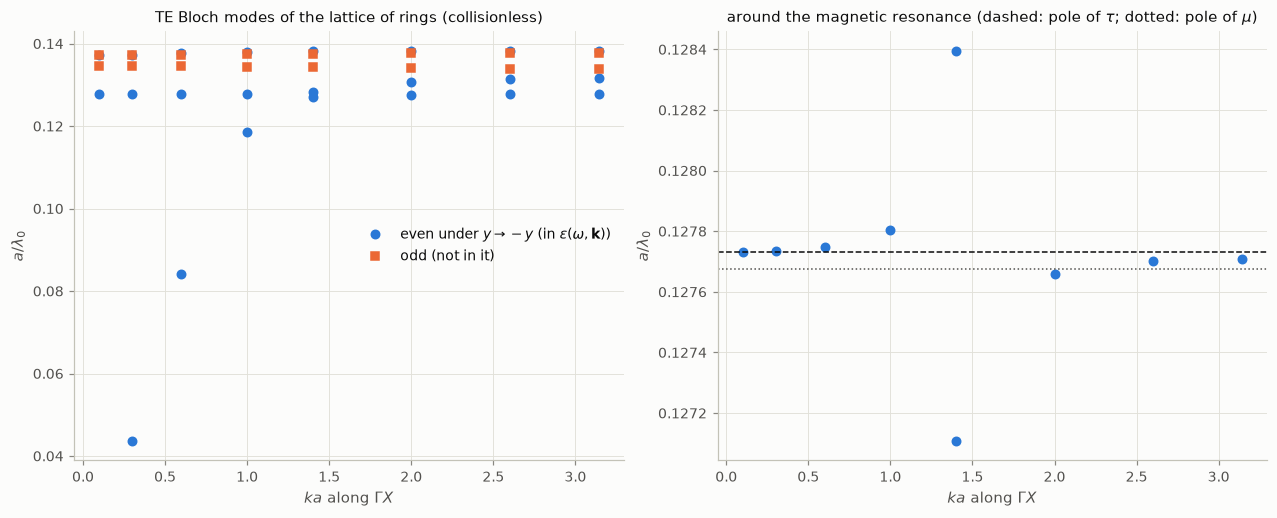

    k a = 0.10: modes between 0.1262 and 0.1290: 0.127731
    k a = 0.60: modes between 0.1262 and 0.1290: 0.127748
    k a = 1.40: modes between 0.1262 and 0.1290: 0.127108, 0.128395
    k a = 2.60: modes between 0.1262 and 0.1290: 0.127701
    highest frequency of the first band over the sampled k (k a > 0.5): 0.127710; f_P = 0.127674; f_m = 0.127730


In [12]:
KA_BANDS = (0.1, 0.3, 0.6, 1.0, 1.4, 2.0, 2.6, np.pi)
t0 = time.perf_counter()
band_pts = []                                           # (ka, f, parity)
for ka in KA_BANDS:
    for fm_ in bloch_scan((ka, 0.0), F_BAND):
        band_pts.append((ka, fm_, mode_parity((ka, 0.0), fm_)))
band_pts = np.array(band_pts)
print(f"band structure along Gamma-X at {len(KA_BANDS)} Bloch vectors: {time.perf_counter() - t0:.0f} s")
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, (lo, hi) in zip(axs, ((0.04, 0.1385), (0.1262, 0.1290))):
    sel = (band_pts[:, 1] >= lo) & (band_pts[:, 1] <= hi)
    ev_ = sel & (band_pts[:, 2] < 0.5)
    od_ = sel & (band_pts[:, 2] >= 0.5)
    ax.plot(band_pts[ev_, 0], band_pts[ev_, 1], "o", color=CAT[0], label=r"even under $y\to-y$ (in $\varepsilon(\omega,\mathbf{k})$)")
    ax.plot(band_pts[od_, 0], band_pts[od_, 1], "s", color=CAT[1], label="odd (not in it)")
    ax.set(xlabel=r"$ka$ along $\Gamma X$", ylabel=r"$a/\lambda_0$")
axs[1].axhline(F_M, color=INK, ls="--", lw=1)
axs[1].axhline(F_P, color=INK2, ls=":", lw=1)
axs[0].legend(loc="center right")
axs[0].set_title("TE Bloch modes of the lattice of rings (collisionless)")
axs[1].set_title(r"around the magnetic resonance (dashed: pole of $\tau$; dotted: pole of $\mu$)")
plt.show()
for ka in KA_BANDS[:: 2]:
    m_ = band_pts[(band_pts[:, 0] == ka) & (band_pts[:, 1] > 0.1262) & (band_pts[:, 1] < 0.1290)]
    print(f"    k a = {ka:.2f}: modes between 0.1262 and 0.1290: " + ", ".join(f"{x:.6f}" for x in m_[:, 1]))
top1 = band_pts[(band_pts[:, 1] > 0.1262) & (band_pts[:, 1] < F_M + 1e-6) & (band_pts[:, 0] > 0.5), 1].max()
print(f"    highest frequency of the first band over the sampled k (k a > 0.5): {top1:.6f}; f_P = {F_P:.6f}; f_m = {F_M:.6f}")
assert F_P < top1 < F_M

The Bloch modes that are even under the mirror satisfy the mode condition to the printed residual, and the ones that are odd do not, as in notebook 03: the odd modes are not in $\varepsilon(\omega,\mathbf k)$. The magnetic mode at small $k$ from the Hermitian condition and the pole of $\tau$ from the driven response, two codes that share only the Mie coefficients and the lattice sums, agree to the printed number.

The figure shows the modes along $\Gamma X$. Near the resonance the lowest band bends over and flattens just below $f_m$, and a second band starts at $f_m$ at $k=0$ (the printed modes near the resonance): the polariton-like pair of a resonance in $\mu$ under a photon line. The printed top of the first band lies between $f_P$ and $f_m$, that is inside the interval in which the second-order $\mu$ is negative; the local model puts the flat band at $f_P$, and the exact band reaches somewhat higher.

### 2.4 The second-order coefficients through the resonance

The cell computes $\varepsilon_T(\omega,0)$, $\tau$, $\delta$ and $\lambda$ on a grid that is coarse far from the resonance and geometric in the detuning close to it, plus a fine grid across the band $f_P<f<f_m$.

second-order coefficients at 172 frequencies (collisionless): 15 s
      f        eps_T       tau        delta      lambda    k0^2 tau      mu        mu_X       mu_M
  0.050103     1.2037   -0.00129   -0.00050    0.00017    -0.0001     0.9999     0.9999     0.9998
  0.100615     1.3975   -0.00065   -0.00187    0.00099    -0.0003     0.9997     1.0005     0.9990
  0.120821     1.9240    0.00364   -0.00826    0.00869     0.0021     1.0021     1.0069     0.9973
  0.125305     2.3978    0.02608   -0.01424    0.02519     0.0162     1.0164     1.0256     1.0074
  0.126958     2.7446    0.10626   -0.01693    0.04458     0.0676     1.0725     1.0851     1.0603
  0.127649     2.9523    1.07359   -0.01740    0.05955     0.6906     3.2322     3.3535     3.1193
  0.127699     2.9693    2.77388   -0.01740    0.06089     1.7858    -1.2727    -1.2548    -1.2911
  0.127750     2.9872   -4.38823   -0.01738    0.06232    -2.8273     0.2613     0.2620     0.2605
  0.127976     3.0704   -0.35387   -0.0172

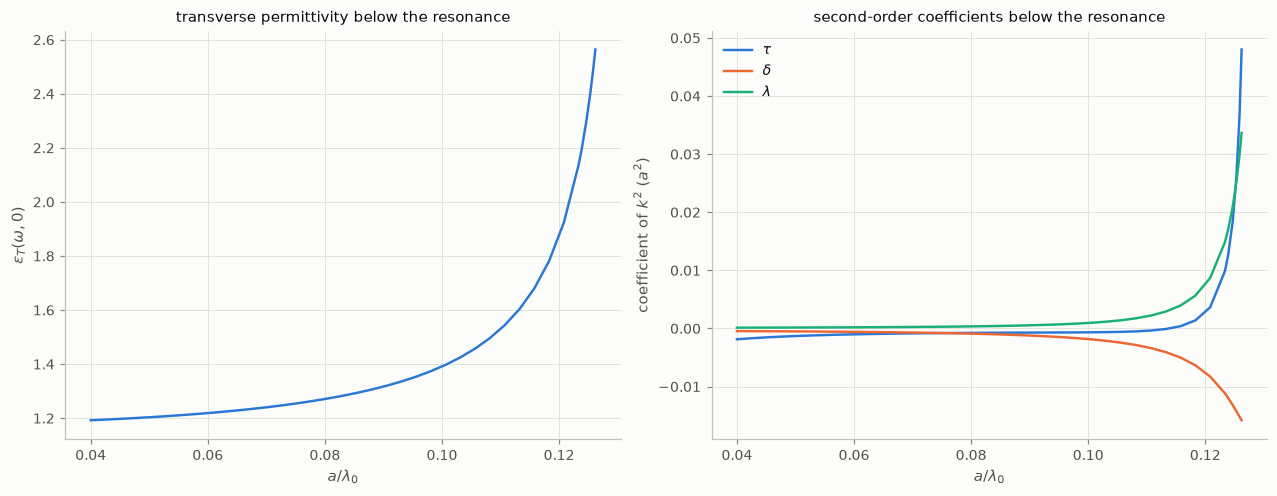

In [13]:
U_DET = np.geomspace(1e-5, 3e-2, 36)
F_DET = np.sort(np.concatenate([F_M * (1 - U_DET), F_M * (1 + U_DET)]))
F_WIDE = np.linspace(0.04, 0.1385, 40)
F_ZOOM = np.linspace(F_P - 2.5e-5, F_M + 1.0e-4, 60)             # resolves the band with Re mu < 0
F_CURVE = np.unique(np.concatenate([F_WIDE, F_DET, F_ZOOM]))
t0 = time.perf_counter()
CO = [coefs(f) for f in F_CURVE]
print(f"second-order coefficients at {len(F_CURVE)} frequencies (collisionless): {time.perf_counter() - t0:.0f} s")
col = lambda key: np.array([c[key] for c in CO])
EPS_T, TAU, DEL, LAM = (col(k).real for k in ("eps", "tau", "delta", "lam"))
K2 = (TWO_PI * F_CURVE) ** 2
MU_I, MU_X, MU_M = (1 / (1 - K2 * (TAU + sg * DEL)) for sg in (0, -1, 1))
below = F_CURVE < F_M
print("      f        eps_T       tau        delta      lambda    k0^2 tau      mu        mu_X       mu_M")
for f_ in (0.05, 0.1, 0.12, 0.125, 0.1270, 0.12765, 0.12770, 0.12775, 0.1280, 0.13, 0.135):
    i = np.argmin(np.abs(F_CURVE - f_))
    print(f"  {F_CURVE[i]:.6f} {EPS_T[i]:10.4f} {TAU[i]:10.5f} {DEL[i]:10.5f} {LAM[i]:10.5f} {K2[i] * TAU[i]:10.4f} {MU_I[i]:10.4f} {MU_X[i]:10.4f} {MU_M[i]:10.4f}")
assert np.abs(np.imag(col("tau"))).max() < 1e-8 * np.abs(TAU).max() + 1e-10
print(f"largest imaginary part of the coefficients (collisionless): {max(np.abs(col(k).imag).max() for k in ('eps', 'tau', 'delta', 'lam')):.1e}")

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.4))
sw = F_CURVE <= 0.1265
axs[0].plot(F_CURVE[sw], EPS_T[sw], color=CAT[0], label=r"$\varepsilon_T(\omega,0)$")
axs[0].set(xlabel=r"$a/\lambda_0$", ylabel=r"$\varepsilon_T(\omega, 0)$", title="transverse permittivity below the resonance")
axs[1].plot(F_CURVE[sw], TAU[sw], color=CAT[0], label=r"$\tau$")
axs[1].plot(F_CURVE[sw], DEL[sw], color=CAT[1], label=r"$\delta$")
axs[1].plot(F_CURVE[sw], LAM[sw], color=CAT[2], label=r"$\lambda$")
axs[1].set(xlabel=r"$a/\lambda_0$", ylabel=r"coefficient of $k^2$ ($a^2$)", title="second-order coefficients below the resonance")
axs[1].legend()
plt.show()

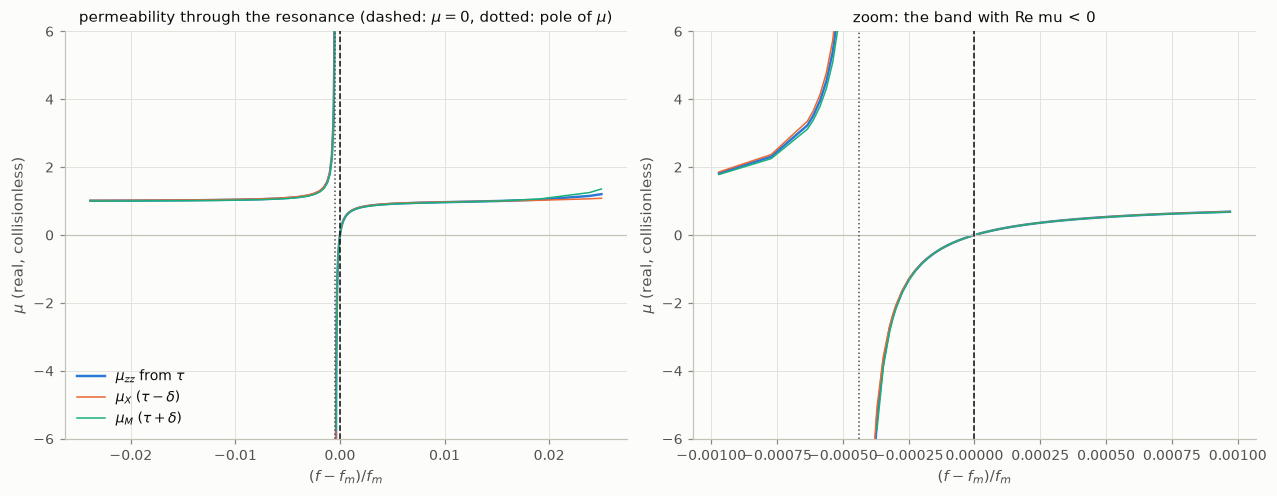

grid points within 3% of f_m with mu < 0: 35; all of them lie between f_P and f_m: True; every grid point between f_P and f_m has mu < 0: True
grid points with mu < 0 elsewhere on the wide grid (f, eps_T, mu): (0.1334, -14.3, -0.11), (0.1385, 5.8, -1.48)


In [14]:
rel = (F_CURVE - F_M) / F_M
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.4))
for ax, lim in zip(axs, (3e-2, 1.2e-3)):
    s_ = np.abs(rel) <= lim
    mu_plot = lambda m: np.where(np.abs(m.real) > 8, np.nan, m.real)
    ax.plot(rel[s_ & below], mu_plot(MU_I)[s_ & below], color=CAT[0], label=r"$\mu_{zz}$ from $\tau$")
    ax.plot(rel[s_ & ~below], mu_plot(MU_I)[s_ & ~below], color=CAT[0])
    ax.plot(rel[s_ & below], mu_plot(MU_X)[s_ & below], color=CAT[1], lw=1.0, label=r"$\mu_X$ ($\tau-\delta$)")
    ax.plot(rel[s_ & ~below], mu_plot(MU_X)[s_ & ~below], color=CAT[1], lw=1.0)
    ax.plot(rel[s_ & below], mu_plot(MU_M)[s_ & below], color=CAT[2], lw=1.0, label=r"$\mu_M$ ($\tau+\delta$)")
    ax.plot(rel[s_ & ~below], mu_plot(MU_M)[s_ & ~below], color=CAT[2], lw=1.0)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.axvline(0, color=INK, ls="--", lw=1)
    ax.axvline((F_P - F_M) / F_M, color=INK2, ls=":", lw=1)
    ax.set(xlabel=r"$(f-f_m)/f_m$", ylabel=r"$\mu$ (real, collisionless)", ylim=(-6, 6))
axs[0].legend(loc="lower left")
axs[0].set_title(r"permeability through the resonance (dashed: $\mu=0$, dotted: pole of $\mu$)")
axs[1].set_title("zoom: the band with Re mu < 0")
plt.show()
neg = (MU_I.real < 0) & (np.abs(rel) < 3e-2)
in_band = (F_CURVE > F_P) & (F_CURVE < F_M)
print(f"grid points within 3% of f_m with mu < 0: {neg.sum()}; all of them lie between f_P and f_m: {bool(np.all(in_band[neg]))}; every grid point between f_P and f_m has mu < 0: {bool(np.all(MU_I.real[in_band] < 0))}")
assert np.all(in_band[neg]) and np.all(MU_I.real[in_band] < 0)
print("grid points with mu < 0 elsewhere on the wide grid (f, eps_T, mu): " + ", ".join(f"({f_:.4f}, {e_:.1f}, {m_:.2f})" for f_, e_, m_ in zip(F_CURVE[(MU_I.real < 0) & ~neg], EPS_T[(MU_I.real < 0) & ~neg], MU_I.real[(MU_I.real < 0) & ~neg])))

## 3. Is it a permeability?

Two things were asked of the dielectric rods in notebooks 03 and 06. First, does the resonant part of $\tau$ dominate the rest of the second-order terms (the Landau-Lifshitz criterion of notebook 01, section 4.1)? Second, does a local model with that $\mu$ reproduce the exact Bloch wavenumber? Here $\tau$ has a pole term of Lorentz form, $k_0^2\tau=A/(f_m^2-f^2)+c_0+c_1f^2$, which the next cell fits on each side of the pole (the window $10^{-3}<|f-f_m|/f_m<10^{-2}$, outside the width of the pole and inside the range where the background is smooth). The pole term is taken as the magnetic part, as the loop term was for the dielectric rods. That identification is not a model: in $C_{4v}$ the circulating mode transforms like $H_z$ (representation $A_2$), and among the first-order field gradients only $\nabla\times\mathbf E$ has that symmetry (the trace is $A_1$, $xx-yy$ is $B_1$, $xy$ is $B_2$), so the pole of the mode can enter only the isotropic transverse coefficient $\tau$ and not $\delta$ or $\lambda$. The cell after the fit prints $\delta$ and $\lambda$ on both sides of the pole as a check of that statement. What is a model is the split of the smooth background of $\tau$ (the pole-plus-smooth fit, the same on both sides), and with it the denominator of the Landau-Lifshitz ratio away from the pole. The ratio is $|\tau_{\rm res}|$ over the largest of $|\delta|$, $|\lambda|$ and $|\tau-\tau_{\rm res}|$; it is evaluated at the detuning from the resonance shown, and is not the static ratio of notebook 03 or the fixed-frequency ratio of notebook 06 (both off resonance), so the numbers are not like for like with those. Near the pole the denominator is $\lambda$, which rises toward the electric resonances of the ring, presumably because they are close (not tested); the cell also prints the ratio with the terms that transverse waves see (without $\lambda$), the ratio with loss, and the crossing against $|\mu-1|$.

Lorentz fit of k0^2 tau = A/(f_m^2 - f^2) + c0 + c1 f^2 (f_m = 0.127730):
   below the pole (10 points): A = 1.4386e-05, c0 = -0.15008, c1 = +8.9761; largest residual / largest value 2.7e-04
   above the pole (11 points): A = 1.4210e-05, c0 = -0.86238, c1 = +52.4489; largest residual / largest value 1.6e-03
PASS  the residue A of the pole of k0^2 tau from the two sides of the resonance (relative): got -0.0122412, target 0, |diff| 1.22e-02 <= 1e-01
   the same residue from k0^2 tau at f_m (1 - 0.002) alone: 1.4115e-05
   width of the Re mu < 0 band predicted by A: (f_m^2 - f_P^2) = A / (1 - c0 - c1 f^2) = 1.433e-05; computed 1.431e-05
PASS  width of the Re mu < 0 band: pole residue against the directly computed f_m^2 - f_P^2 (relative): got 0.0015538, target 0, |diff| 1.55e-03 <= 5e-02

Landau-Lifshitz ratio |tau_res| / max(|delta|, |lambda|, |tau - tau_res|), the pole term of the Lorentz fit as the magnetic part (a model split):
   (f - f_m)/f_m      mu_zz      (mu_X - mu_M)/(mu - 1)  

     -3.0e-03      +1.1665            +0.1812                4.401     0.22989   0.01731   0.05224   0.00699
     -1.0e-03      +1.7761            +0.0910               11.765     0.68622   0.01740   0.05833   0.00643
     -3.0e-04      -2.1572            -0.0330               37.616     2.28340   0.01740   0.06070   0.00974
     -1.0e-04      -0.2945            -0.0015              111.498     6.84678   0.01739   0.06141   0.02079
     +1.0e-04      +0.1852            -0.0009              110.158     6.84336   0.01739   0.06212   0.01403


     +1.0e-03      +0.6939            -0.0352               10.425     0.68280   0.01732   0.06550   0.00080
     +1.0e-02      +0.9691            -0.4779                0.554     0.06677   0.01195   0.12041   0.01829
below the pole the ratio grows monotonically: [1.45, 1.9, 4.4, 11.76, 37.62, 111.5] for detunings [-0.03, -0.01, -0.003, -0.001, -0.0003, -0.0001]; it passes 10 at (f_m - f)/f_m = 1.2e-03
anisotropy (mu_X - mu_M)/(mu - 1): +1.908 at 3% below the pole, +0.091 at 0.1% below, -0.0015 at 0.01% below
delta and lambda across the pole (u = -1e-4, +1e-4): delta -0.01739, -0.01739; lambda 0.06141, 0.06212; tau_res 6.85, -6.84
PASS  delta has no pole: relative change across the pole (u = -1e-4 to +1e-4), while tau_res changes sign: got -0.000445915, target 0, |diff| 4.46e-04 <= 1e-02
PASS  lambda has no pole: relative change across the pole: got 0.0116562, target 0, |diff| 1.17e-02 <= 5e-02
ratio without lambda (delta and tau - tau_res only) at [-0.03, -0.01, -0.003, -0.001, -0.000

   f_gamma/f_p = 0.0033 (96 detunings, f_gamma/f_m = 5.22e-03): with lambda maximum 4.440 at u = +3.04e-05; without lambda maximum 15.217 at u = +9.22e-05
      with lambda, every fourth point of the grid ordered by u (from the most negative): [1.4, 1.75, 1.93, 2.08, 2.38, 2.7, 3.16, 3.77, 4.21, 4.39, 4.37, 4.44, 1.68, 4.38, 4.28, 4.09, 3.59, 2.63, 1.97, 1.4, 1.07, 0.83, 0.62, 0.26]


   f_gamma/f_p = 0.0333 (96 detunings, f_gamma/f_m = 5.22e-02): with lambda maximum 1.574 at u = +4.40e-05; without lambda maximum 2.259 at u = +1.30e-02
      with lambda, every fourth point of the grid ordered by u (from the most negative): [0.99, 1.03, 1.08, 1.18, 1.29, 1.08, 0.92, 0.82, 0.8, 0.78, 0.71, 0.81, 1.11, 1.57, 0.95, 0.85, 0.88, 1.01, 1.57, 1.12, 1.0, 1.03, 1.24, 0.95]


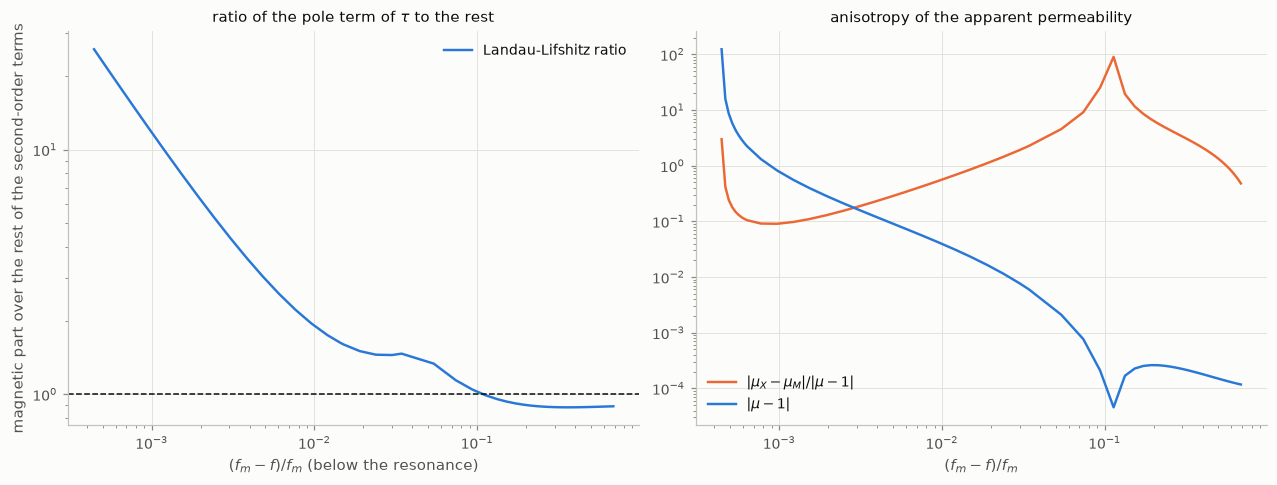

In [15]:
def lorentz_fit(F, ktau, fm, side, rmax=1e-2):
    """Fit k0^2 tau = A / (fm^2 - f^2) + c0 + c1 f^2 on one side of the pole, 1e-3 < |f - fm| / fm < rmax (linear least squares for A, c0, c1)."""
    rel_ = np.abs(F - fm) / fm
    sel = (rel_ > 1e-3) & (rel_ < rmax) & ((F < fm) if side < 0 else (F > fm))
    f_ = F[sel]
    Amat = np.stack([1 / (fm**2 - f_**2), np.ones_like(f_), f_**2], 1)
    coef, *_ = np.linalg.lstsq(Amat, ktau[sel], rcond=None)
    return coef, np.abs(Amat @ coef - ktau[sel]).max() / np.abs(ktau[sel]).max(), sel.sum()


KT = K2 * TAU
cf_lo, res_lo, n_lo = lorentz_fit(F_CURVE, KT, F_M, -1)
cf_hi, res_hi, n_hi = lorentz_fit(F_CURVE, KT, F_M, +1)
print(f"Lorentz fit of k0^2 tau = A/(f_m^2 - f^2) + c0 + c1 f^2 (f_m = {F_M:.6f}):")
print(f"   below the pole ({n_lo} points): A = {cf_lo[0]:.4e}, c0 = {cf_lo[1]:+.5f}, c1 = {cf_lo[2]:+.4f}; largest residual / largest value {res_lo:.1e}")
print(f"   above the pole ({n_hi} points): A = {cf_hi[0]:.4e}, c0 = {cf_hi[1]:+.5f}, c1 = {cf_hi[2]:+.4f}; largest residual / largest value {res_hi:.1e}")
A_RES = cf_lo[0]
check("the residue A of the pole of k0^2 tau from the two sides of the resonance (relative)", cf_hi[0] / cf_lo[0] - 1, 0.1)
print(f"   the same residue from k0^2 tau at f_m (1 - 0.002) alone: {(F_M**2 - (F_M * 0.998) ** 2) * (TWO_PI * F_M * 0.998) ** 2 * coefs(F_M * 0.998)['tau'].real:.4e}")
print(f"   width of the Re mu < 0 band predicted by A: (f_m^2 - f_P^2) = A / (1 - c0 - c1 f^2) = {A_RES / (1 - cf_lo[1] - cf_lo[2] * F_M**2):.3e}; computed {F_M**2 - F_P**2:.3e}")
check("width of the Re mu < 0 band: pole residue against the directly computed f_m^2 - f_P^2 (relative)", A_RES / (1 - cf_lo[1] - cf_lo[2] * F_M**2) / (F_M**2 - F_P**2) - 1, 0.05)


def tau_split(f, c):
    """Mean-field (resonant) part of tau from the Lorentz pole term, and the rest."""
    t_res = A_RES / ((TWO_PI * f) ** 2 * (F_M**2 - f**2))
    return t_res, c["tau"] - t_res


def ll_ratio(f, c):
    t_res, t_bg = tau_split(f, c)
    return abs(t_res) / max(abs(c["delta"]), abs(c["lam"]), abs(t_bg))


print("\nLandau-Lifshitz ratio |tau_res| / max(|delta|, |lambda|, |tau - tau_res|), the pole term of the Lorentz fit as the magnetic part (a model split):")
print("   (f - f_m)/f_m      mu_zz      (mu_X - mu_M)/(mu - 1)      LL ratio    |tau_res|   |delta|    |lambda|   |tau - tau_res|")
LL, ANI = {}, {}
for u in (-3e-2, -1e-2, -3e-3, -1e-3, -3e-4, -1e-4, 1e-4, 1e-3, 1e-2):
    f_ = F_M * (1 + u)
    c = coefs(f_)
    mI, mX, mM = mu_of(f_, c)
    t_res, t_bg = tau_split(f_, c)
    LL[u], ANI[u] = ll_ratio(f_, c), ((mX - mM) / (mI - 1)).real
    print(f"   {u:+10.1e}   {mI.real:+10.4f}     {ANI[u]:+14.4f}            {LL[u]:9.3f}   {abs(t_res):9.5f} {abs(c['delta']):9.5f} {abs(c['lam']):9.5f} {abs(t_bg):9.5f}")
RLL = np.array([ll_ratio(f_, c) for f_, c in zip(F_CURVE, CO)])
ANIS = ((MU_X - MU_M) / (MU_I - 1)).real
u_below = [u for u in sorted(LL) if u < 0]
rat_below = np.array([LL[u] for u in u_below])
assert (np.diff(rat_below) > 0).all(), "the ratio grows toward the pole from below"
u10 = -np.exp(np.interp(np.log(10.0), np.log(rat_below), np.log(-np.array(u_below))))
print(f"below the pole the ratio grows monotonically: {np.round(rat_below, 2).tolist()} for detunings {u_below}; it passes 10 at (f_m - f)/f_m = {-u10:.1e}")
assert LL[-3e-2] < 2.5 and LL[-1e-4] > 100 and LL[1e-2] < 1.0
print(f"anisotropy (mu_X - mu_M)/(mu - 1): {ANI[-3e-2]:+.3f} at 3% below the pole, {ANI[-1e-3]:+.3f} at 0.1% below, {ANI[-1e-4]:+.4f} at 0.01% below")
assert abs(ANI[-1e-4]) < abs(ANI[-1e-3]) < abs(ANI[-1e-2]) < abs(ANI[-3e-2])

# symmetry: the pole of the circulating mode (A2) appears in tau only
cL, cH = coefs(F_M * (1 - 1e-4)), coefs(F_M * (1 + 1e-4))
print(f"delta and lambda across the pole (u = -1e-4, +1e-4): delta {cL['delta'].real:.5f}, {cH['delta'].real:.5f}; lambda {cL['lam'].real:.5f}, {cH['lam'].real:.5f}; tau_res {tau_split(F_M * (1 - 1e-4), cL)[0]:.2f}, {tau_split(F_M * (1 + 1e-4), cH)[0]:.2f}")
check("delta has no pole: relative change across the pole (u = -1e-4 to +1e-4), while tau_res changes sign", cH["delta"].real / cL["delta"].real - 1, 1e-2)
check("lambda has no pole: relative change across the pole", cH["lam"].real / cL["lam"].real - 1, 5e-2)
assert tau_split(F_M * (1 - 1e-4), cL)[0] * tau_split(F_M * (1 + 1e-4), cH)[0] < 0

# the ratio without lambda (what transverse waves see), the crossing, and |mu - 1| at the crossing
def ll_transverse(f, c, tr=None):
    t_res, t_bg = tau_split(f, c)
    return abs(t_res) / max(abs(c["delta"]), abs(t_bg))


rat_T = np.array([ll_transverse(F_M * (1 + u), coefs(F_M * (1 + u))) for u in u_below])
uT = -np.exp(np.interp(np.log(10.0), np.log(rat_T), np.log(-np.array(u_below))))
print(f"ratio without lambda (delta and tau - tau_res only) at {u_below}: {np.round(rat_T, 2).tolist()}; it passes 10 at (f_m - f)/f_m = {-uT:.1e}, against {-u10:.1e} with lambda")
print("  below the pole lambda is the largest of the other terms close to the pole (printed table): it rises from the far-field value toward the electric resonances of the ring (the lowest is at f = 0.1366), presumably because they are close (not tested)")
check("crossing of 10 without lambda, (f_m - f)/f_m (interpolated between table rows, order of magnitude)", np.log10(-uT), 0.3, np.log10(4e-3))
mu_cross = [mu_of(F_M * (1 + u), coefs(F_M * (1 + u)))[0].real for u in u_below]
mu_at10 = np.interp(np.log(10.0), np.log(rat_below), np.array(mu_cross))
print(f"|mu - 1| where the ratio (with lambda) passes 10 (interpolated): {abs(mu_at10 - 1):.2f}; mu at the table rows {u_below}: {np.round(mu_cross, 3).tolist()}")
print("  so 'ratio above 10' is the statement 'mu differs from 1 by more than about a half': a narrow resonance shrinks any crossing measured in detuning")

# with loss: the resonant part is the lossy tau minus the smooth collisionless background (same A, same fitted split)
BG_CACHE = {}


def tau_bg_smooth(f):
    """Smooth collisionless background of tau: collisionless tau minus its pole term."""
    if f not in BG_CACHE:
        BG_CACHE[f] = coefs(f)["tau"].real - A_RES / ((TWO_PI * f) ** 2 * (F_M**2 - f**2))
    return BG_CACHE[f]


def ll_loss(f, loss):
    """Landau-Lifshitz ratios with loss, with and without lambda: resonant part = lossy tau - smooth collisionless background."""
    c = coefs(f, loss)
    tb = tau_bg_smooth(f)
    t_r = abs(c["tau"] - tb)
    return t_r / max(abs(c["delta"]), abs(c["lam"]), abs(tb)), t_r / max(abs(c["delta"]), abs(tb))


print("ratio with loss (resonant part = tau with loss minus the smooth collisionless background; |.| of complex terms), u = (f - f_m)/f_m:")
LL_LOSS = {}
LOSS_MAIN = (1 / 300, 1 / 30)
for loss in LOSS_MAIN:
    w_rel = loss * FP / F_M                              # f_gamma / f_m, the relative scale of the loss width
    U_GEO = np.geomspace(1e-5, 5e-2, 24)
    U_LIN = np.arange(-2.0, 2.0 + 1e-9, 1 / 12) * w_rel  # spacing f_gamma / (12 f_m): under f_gamma / 10 across the peak
    U_L = np.unique(np.round(np.concatenate([-U_GEO, U_GEO, U_LIN]), 12))
    U_L = U_L[np.abs(U_L) > 1e-9]                        # the collisionless pole itself (u = 0) is excluded
    res_ = np.array([ll_loss(F_M * (1 + u), loss) for u in U_L])
    r_all, r_tr = res_[:, 0], res_[:, 1]
    i_all, i_tr = int(np.argmax(r_all)), int(np.argmax(r_tr))
    LL_LOSS[loss] = (r_all[i_all], r_tr[i_tr])
    print(f"   f_gamma/f_p = {loss:.4f} ({len(U_L)} detunings, f_gamma/f_m = {w_rel:.2e}): with lambda maximum {r_all[i_all]:.3f} at u = {U_L[i_all]:+.2e}; without lambda maximum {r_tr[i_tr]:.3f} at u = {U_L[i_tr]:+.2e}")
    print(f"      with lambda, every fourth point of the grid ordered by u (from the most negative): {np.round(r_all[::4], 2).tolist()}")
assert np.isfinite([v for p_ in LL_LOSS.values() for v in p_]).all() and LL_LOSS[1 / 30][0] < LL_LOSS[1 / 300][0]
assert LL_LOSS[1 / 300][0] < 5.0 and LL_LOSS[1 / 30][0] < 2.0

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.3))
sl = (rel < 0) & (F_CURVE < F_P * (1 - 2e-6))
axs[0].loglog(-rel[sl], RLL[sl], color=CAT[0], label="Landau-Lifshitz ratio")
axs[0].axhline(1.0, color=INK, ls="--", lw=1)
axs[0].set(xlabel=r"$(f_m-f)/f_m$ (below the resonance)", ylabel="magnetic part over the rest of the second-order terms", title="ratio of the pole term of $\\tau$ to the rest")
axs[0].legend()
sa = sl & (np.abs(MU_I - 1) > 1e-6)
axs[1].loglog(-rel[sa], np.abs(ANIS[sa]), color=CAT[1], label=r"$|\mu_X-\mu_M|/|\mu-1|$")
axs[1].loglog(-rel[sa], np.abs(MU_I[sa] - 1), color=CAT[0], label=r"$|\mu-1|$")
axs[1].set(xlabel=r"$(f_m-f)/f_m$", title="anisotropy of the apparent permeability")
axs[1].legend()
plt.show()

The ratio is of order one at a few percent below the resonance, grows steadily toward the pole, and passes 10 about a tenth of a percent below the pole (printed); above the resonance it is already below one at one percent. The pole term dominates the second-order response only close to the pole; farther away the response is a sum of terms of comparable size, and there a permeability is not a meaningful description in the Landau-Lifshitz sense, although $\mu-1$ is also small there. The anisotropy follows the same pattern: $(\mu_X-\mu_M)/(\mu-1)$ is large at a few percent below the resonance and small within a tenth of a percent (the figure and table), presumably because the resonant pole dominates $\tau\mp\delta$ alike there. With loss the resonant part is the lossy $\tau$ minus the smooth collisionless background, and the ratio no longer grows without bound: its printed maximum is 4.4 for $f_\gamma/f_p=1/300$ and 1.6 for $1/30$ with $\lambda$ in the denominator, and 15 and 2.3 without $\lambda$.

**The local model.** With $\varepsilon_T(\omega,0)$ and one of the permeabilities, $k=k_0\sqrt{\varepsilon_T\mu}$. The exact Bloch wavenumber along a symmetry direction solves $k^2=k_0^2\varepsilon_T(\omega,k)$ with the full function (secant iteration along the first band, continued from low frequency). The cell compares the two for the first band up to just below $f_P$.

exact Bloch wavenumbers along Gamma-X and Gamma-M at 20 frequencies below f_P: 4 s
       f        k_X a (exact)   mu = 1     mu_iso     mu_X      | (k_M - k_X)/k_X: exact   from delta
   0.030000      0.20516   +4.77e-05  -7.27e-06  +9.86e-09   |       -1.454e-05   -1.457e-05
   0.070000      0.48983   +1.43e-05  -6.70e-05  +5.67e-07   |       -1.339e-04   -1.350e-04
   0.120000      1.03451   -2.83e-03  -2.07e-03  +8.47e-05   |       -4.152e-03   -4.289e-03
   0.125759      1.26310   -1.53e-02  -4.46e-03  +3.50e-04   |       -9.178e-03   -9.551e-03
   0.127163      1.41111   -5.23e-02  -4.03e-03  +2.05e-03   |       -1.110e-02   -1.203e-02
   0.127546      1.60740   -1.48e-01  +1.99e-02  +2.82e-02   |       -1.283e-02   -1.590e-02
   0.127649      1.91927   -2.82e-01  +2.81e-01  +3.05e-01   |       -2.292e-02   -3.505e-02
   0.127668      2.06865   -3.33e-01  +1.08e+00  +1.21e+00   |       -3.292e-02   -1.038e-01
PASS  far below the resonance the local model with mu_X reproduces the 

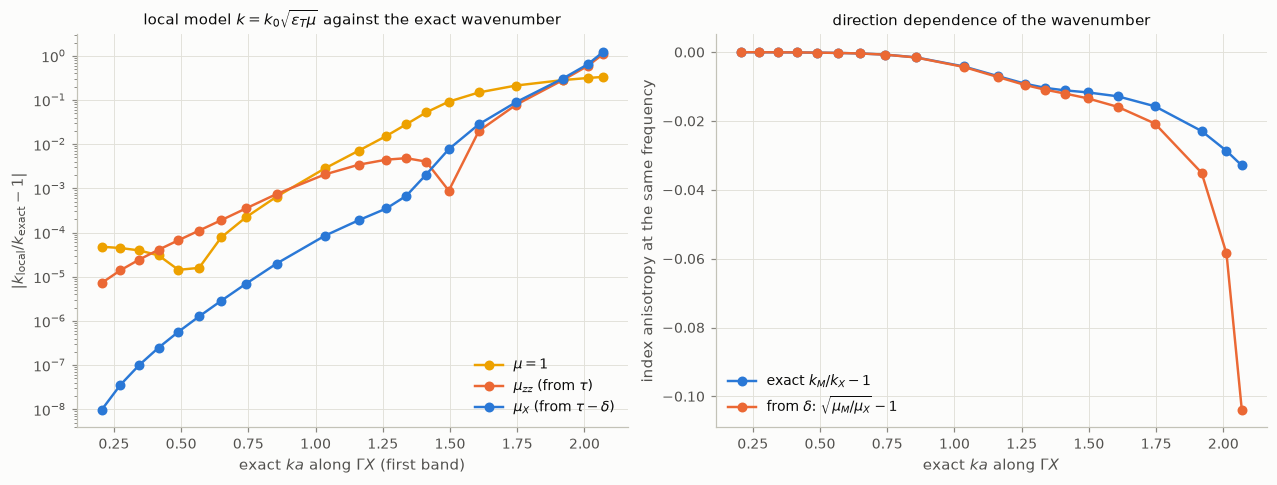

In [16]:
def bloch_k(f, phi, guess, loss=0.0, M=4, tol=1e-12):
    """Bloch wavenumber (first band, extended zone) along phi from k^2 = k0^2 eps_T(w, k) with the full function, secant iteration."""
    k0 = TWO_PI * f
    rods = ring(eps_drude(f, FP, loss * FP))
    g = lambda kap: k0**2 * eps_parts(k0, kap, phi, rods, M)[0] - kap**2
    k1, k2 = guess, guess * 1.001 + 1e-4
    g1, g2 = g(k1), g(k2)
    for _ in range(80):
        k3 = k2 - g2 * (k2 - k1) / (g2 - g1)
        if abs(k3 - k2) < tol:
            return k3
        k1, g1, k2, g2 = k2, g2, k3, g(k3)
    return np.nan


F_REACH = np.concatenate([np.linspace(0.03, 0.12, 10), F_P * (1 - np.array([3e-2, 1.5e-2, 8e-3, 4e-3, 2e-3, 1e-3, 5e-4, 2e-4, 1e-4, 5e-5]))])
rows, prevX, prevM, prev_f = [], None, None, None
t0 = time.perf_counter()
for f_ in F_REACH:
    c = coefs(f_)
    mI, mX, mM = (m.real for m in mu_of(f_, c))
    k0 = TWO_PI * f_
    loc = lambda mu: k0 * np.sqrt(c["eps"].real * mu)
    gX = loc(mX) if prevX is None else prevX * f_ / prev_f
    gM = loc(mM) if prevM is None else prevM * f_ / prev_f
    kX, kM = bloch_k(f_, 0.0, gX).real, bloch_k(f_, np.pi / 4, gM).real
    prevX, prevM, prev_f = kX, kM, f_
    rows.append((f_, kX, kM, loc(1.0), loc(mI), loc(mX), loc(mM)))
rows = np.array(rows)
print(f"exact Bloch wavenumbers along Gamma-X and Gamma-M at {len(F_REACH)} frequencies below f_P: {time.perf_counter() - t0:.0f} s")
print("       f        k_X a (exact)   mu = 1     mu_iso     mu_X      | (k_M - k_X)/k_X: exact   from delta")
for r_ in rows[[0, 4, 9, 11, 13, 15, 17, 19]]:
    f_, kX, kM, k1, kI, kx, km = r_
    print(f"  {f_:9.6f} {kX:12.5f} {k1 / kX - 1:+11.2e} {kI / kX - 1:+10.2e} {kx / kX - 1:+10.2e}   | {kM / kX - 1:+16.3e} {km / kx - 1:+12.3e}")
sel_low = rows[:, 0] < 0.11
check("far below the resonance the local model with mu_X reproduces the exact wavenumber (largest relative error, f < 0.11)", np.abs(rows[sel_low, 5] / rows[sel_low, 1] - 1).max(), 1e-3)
assert np.abs(rows[sel_low, 5] / rows[sel_low, 1] - 1).max() < np.abs(rows[sel_low, 3] / rows[sel_low, 1] - 1).max()
err_mx = np.abs(rows[:, 5] / rows[:, 1] - 1)
print(f"error of the mu_X model: {err_mx[10]:.1e} at f = {rows[10, 0]:.5f} (k a = {rows[10, 1]:.2f}), {err_mx[-1]:.1e} at f = {rows[-1, 0]:.6f} (k a = {rows[-1, 1]:.2f})")
ani_ratio = (rows[-1, 6] / rows[-1, 5] - 1) / (rows[-1, 2] / rows[-1, 1] - 1)
print(f"index anisotropy from delta over the exact one at the last point: {ani_ratio:.2f}")
assert 2 < ani_ratio < 4
i1 = int(np.argmax(err_mx > 1e-2))
k_1pct = np.interp(1e-2, err_mx[i1 - 1:i1 + 1], rows[i1 - 1:i1 + 1, 1])
print(f"the mu_X model is within 1 percent of the exact wavenumber up to k a = {k_1pct:.2f} (f = {np.interp(k_1pct, rows[:, 1], rows[:, 0]):.6f}); the exact first band reaches k a = {rows[-1, 1]:.2f} at the last point, f_P - f = {F_P - rows[-1, 0]:.1e}")

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.3))
axs[0].semilogy(rows[:, 1], np.abs(rows[:, 3] / rows[:, 1] - 1), "o-", color=CAT[3], label=r"$\mu=1$")
axs[0].semilogy(rows[:, 1], np.abs(rows[:, 4] / rows[:, 1] - 1), "o-", color=CAT[1], label=r"$\mu_{zz}$ (from $\tau$)")
axs[0].semilogy(rows[:, 1], np.abs(rows[:, 5] / rows[:, 1] - 1), "o-", color=CAT[0], label=r"$\mu_X$ (from $\tau-\delta$)")
axs[0].set(xlabel=r"exact $k a$ along $\Gamma X$ (first band)", ylabel=r"$|k_{\rm local}/k_{\rm exact}-1|$", title=r"local model $k=k_0\sqrt{\varepsilon_T\mu}$ against the exact wavenumber")
axs[0].legend(loc="lower right")
axs[1].plot(rows[:, 1], rows[:, 2] / rows[:, 1] - 1, "o-", color=CAT[0], label=r"exact $k_M/k_X-1$")
axs[1].plot(rows[:, 1], rows[:, 6] / rows[:, 5] - 1, "o-", color=CAT[1], label=r"from $\delta$: $\sqrt{\mu_M/\mu_X}-1$")
axs[1].set(xlabel=r"exact $k a$ along $\Gamma X$", ylabel="index anisotropy at the same frequency", title="direction dependence of the wavenumber")
axs[1].legend()
plt.show()

Far below the resonance the local model with $\mu_X$ reproduces the exact wavenumber to the printed accuracy, and it stays within one percent until the Bloch wavenumber reaches the printed value of $ka$; closer to the resonance it fails, with the error growing with $ka$ (left panel), presumably because the fourth-order terms take over as the band flattens toward the zone edge (not tested). The anisotropy of the index is followed by the model while it is small and is overestimated, by the printed factor at the last point, close to the pole. The last cell of this section compares the local model with the first-band modes of the Hermitian calculation, which share only the Mie coefficients and the lattice sums with the driven response, and then looks at the upper band just above $f_m$. The first band agrees with the local model to the printed accuracy. In the upper band $f-f_m$ divided by $k^2$ is nearly the same at both Bloch vectors (printed): the band is the shift of the pole with $k$, which an expansion in $k$ at fixed frequency does not represent, and the local model gives only the printed fraction of the distance above $f_m$.

In [17]:
print("the local model k = k0 sqrt(eps_T mu_X) against the Bloch modes of the Hermitian calculation (independent of the driven response)")
print("  first band, along Gamma-X:      k a     f (Bloch mode)     k_local a      relative difference")
worst_b1 = 0.0
for ka in (0.3, 0.6, 1.0):
    fB = band_pts[(band_pts[:, 0] == ka) & (band_pts[:, 1] < 0.125) & (band_pts[:, 1] > 0.03), 1]
    assert len(fB) == 1
    c = coefs(fB[0])
    k_loc = TWO_PI * fB[0] * np.sqrt(c["eps"].real * mu_of(fB[0], c)[1].real)
    worst_b1 = max(worst_b1, abs(k_loc / ka - 1))
    print(f"                                 {ka:5.2f} {fB[0]:15.6f} {k_loc:14.5f} {k_loc / ka - 1:+14.2e}")
check("first Bloch band (Hermitian calculation) against the local model with eps_T and mu_X at k a = 0.3, 0.6, 1.0 (relative error of k)", worst_b1, 1e-3)

print("  upper band near Gamma:  k a    f - f_m (Bloch)    (f - f_m)/k^2     f - f_m from the local model, over the exact one")
for ka in (0.1, 0.3):
    fB = band_pts[(band_pts[:, 0] == ka) & (band_pts[:, 1] > F_M - 1e-6) & (band_pts[:, 1] < F_M + 2e-4), 1]
    assert len(fB) == 1

    def gmod(f, ka=ka):
        c = coefs(f, rho=0.01)
        return (TWO_PI * f) ** 2 * c["eps"].real / (1 - (TWO_PI * f) ** 2 * (c["tau"] - c["delta"]).real) - ka**2

    f_mod = brentq(gmod, F_M + 0.2 * (fB[0] - F_M), fB[0] + 2e-6, xtol=1e-14)
    print(f"                         {ka:5.2f} {fB[0] - F_M:15.3e} {(fB[0] - F_M) / ka**2:17.3e} {(f_mod - F_M) / (fB[0] - F_M):28.3f}")
print("  in the upper band the frequency above f_m is the shift of the pole with k, (f - f_m) = c k^2 with c of the printed size; the second-order model, which holds k fixed")
print("  while the frequency moves, needs |f - f_m| much larger than c k^2 and does not describe this band")
assert 0.4 < (f_mod - F_M) / (fB[0] - F_M) < 0.9

the local model k = k0 sqrt(eps_T mu_X) against the Bloch modes of the Hermitian calculation (independent of the driven response)
  first band, along Gamma-X:      k a     f (Bloch mode)     k_local a      relative difference
                                  0.30        0.043659        0.30000      +5.36e-08
                                  0.60        0.084148        0.60000      +1.76e-06


                                  1.00        0.118558        1.00007      +6.58e-05
PASS  first Bloch band (Hermitian calculation) against the local model with eps_T and mu_X at k a = 0.3, 0.6, 1.0 (relative error of k): got 6.5823e-05, target 0, |diff| 6.58e-05 <= 1e-03
  upper band near Gamma:  k a    f - f_m (Bloch)    (f - f_m)/k^2     f - f_m from the local model, over the exact one


                          0.10       4.423e-07         4.423e-05                        0.664


                          0.30       4.093e-06         4.547e-05                        0.674
  in the upper band the frequency above f_m is the shift of the pole with k, (f - f_m) = c k^2 with c of the printed size; the second-order model, which holds k fixed
  while the frequency moves, needs |f - f_m| much larger than c k^2 and does not describe this band


## 4. Loss and size

**Loss.** $f_\gamma/f_p=1/300$ and $1/30$, applied to the same structure; the second-order coefficients become complex and $\mu_{zz}$ is complex. The cell prints the extremes of $\mathrm{Re}\,\mu$ and $\mathrm{Im}\,\mu$ within one percent of the resonance (the electric resonances of the ring lie further up and are excluded), and the figure of merit $-\mathrm{Re}\,\mu/\mathrm{Im}\,\mu$ where $\mathrm{Re}\,\mu<0$. The extremes are values on a grid that is geometric in the detuning, and are indicative at the level of a few percent at best. A second cell scans smaller losses on a grid fine enough for the narrow band.

In [18]:
def mu_curve(F, loss, fp=FP, s=S_RING, r=R_ROD, n=4):
    """mu_zz(f) from tau for the lattice of rings with f_gamma / f_p = loss."""
    cs = [coefs(f, loss, fp, s, r, n=n) for f in F]
    tau = np.array([c["tau"] for c in cs])
    return 1 / (1 - (TWO_PI * np.asarray(F)) ** 2 * tau), cs


def band_summary(F, mu, fm, rmax=1e-2):
    """Extremes of mu within rmax of the resonance (the electric resonances of the ring lie further up and are excluded)."""
    w = np.abs(F - fm) / fm < rmax
    F, mu = F[w], mu[w]
    neg = mu.real < 0
    i_min, i_im = int(np.argmin(mu.real)), int(np.argmax(mu.imag))
    fom = (-mu.real / mu.imag)[neg].max() if neg.any() else np.nan
    return dict(min_re=mu.real[i_min], f_min=F[i_min], max_re=mu.real.max(), max_im=mu.imag[i_im], f_im=F[i_im], n_neg=int(neg.sum()), fom=fom)


LOSS_MAIN = (1 / 300, 1 / 30)

mu(f) with loss: 9 s
f_gamma/f_p     min Re mu   at f           max Re mu    max Im mu   at f         points with Re mu < 0   best -Re mu/Im mu
     0.0033        0.915  0.127972       1.080        0.170  0.127669            0                    nan
     0.0333        0.976  0.128693       0.994        0.019  0.128338            0                    nan
lossless, for comparison: Re mu < 0 on the whole band (f_P, f_m), where Im mu = 0, so -Re mu/Im mu is infinite there


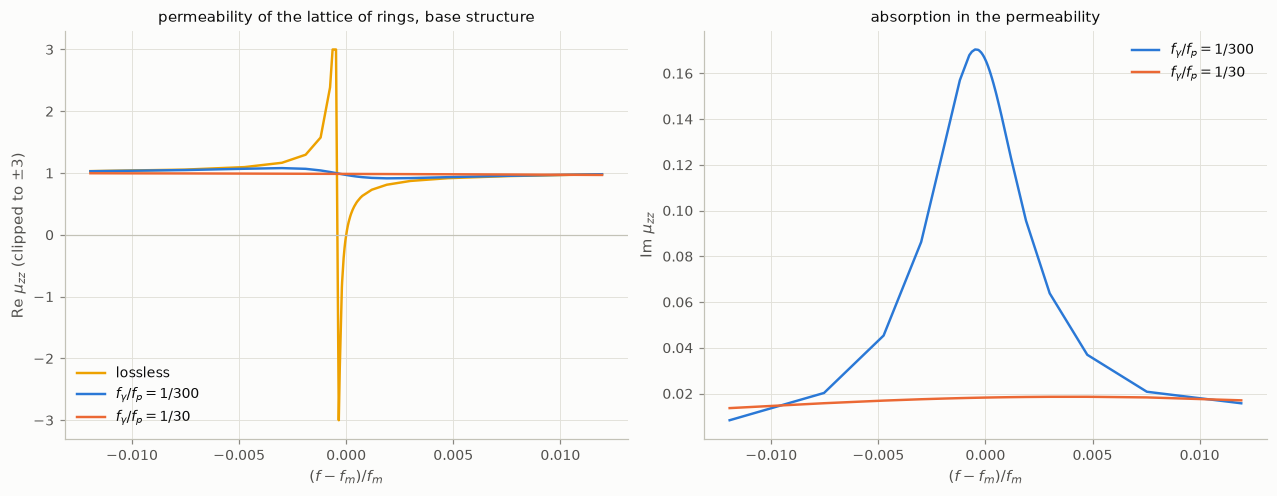

In [19]:
U_LOSS = np.geomspace(3e-5, 3e-2, 16)
F_LOSS = np.sort(np.concatenate([F_M * (1 - U_LOSS), F_M * (1 + U_LOSS), F_ZOOM[::6]]))
t0 = time.perf_counter()
MU_LOSS = {}
for loss in LOSS_MAIN:
    MU_LOSS[loss], _ = mu_curve(F_LOSS, loss)
MU_LOSS[0.0], _ = mu_curve(F_LOSS, 0.0)
print(f"mu(f) with loss: {time.perf_counter() - t0:.0f} s")
print("f_gamma/f_p     min Re mu   at f           max Re mu    max Im mu   at f         points with Re mu < 0   best -Re mu/Im mu")
SUM = {}
for loss in LOSS_MAIN:
    SUM[loss] = band_summary(F_LOSS, MU_LOSS[loss], F_M)
    sm = SUM[loss]
    print(f"{loss:11.4f} {sm['min_re']:12.3f}  {sm['f_min']:.6f} {sm['max_re']:11.3f} {sm['max_im']:12.3f}  {sm['f_im']:.6f} {sm['n_neg']:12d} {sm['fom']:22.2f}")
assert SUM[1 / 300]["n_neg"] == 0 and SUM[1 / 30]["n_neg"] == 0
assert SUM[1 / 30]["max_im"] < SUM[1 / 300]["max_im"]
print("lossless, for comparison: Re mu < 0 on the whole band (f_P, f_m), where Im mu = 0, so -Re mu/Im mu is infinite there")

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.4))
sw = np.abs(F_LOSS - F_M) / F_M < 1.2e-2
for loss, c_, lab in ((0.0, CAT[3], "lossless"), (1 / 300, CAT[0], r"$f_\gamma/f_p=1/300$"), (1 / 30, CAT[1], r"$f_\gamma/f_p=1/30$")):
    m_ = MU_LOSS[loss][sw]
    axs[0].plot(((F_LOSS - F_M) / F_M)[sw], np.clip(m_.real, -3, 3), color=c_, label=lab)
    if loss:
        axs[1].plot(((F_LOSS - F_M) / F_M)[sw], m_.imag, color=c_, label=lab)
axs[0].axhline(0, color=AXIS, lw=0.8)
axs[0].set(xlabel=r"$(f-f_m)/f_m$", ylabel=r"Re $\mu_{zz}$ (clipped to $\pm3$)", title=r"permeability of the lattice of rings, base structure")
axs[0].legend(loc="lower left")
axs[1].set(xlabel=r"$(f-f_m)/f_m$", ylabel=r"Im $\mu_{zz}$", title="absorption in the permeability")
axs[1].legend()
plt.show()

In [20]:
print("loss scan at the base structure (a/lambda_0 sampled every 5e-6 from just below f_P to 1e-4 above f_m)")
print("f_gamma/f_p    min Re mu      max Im mu    points Re mu < 0    best -Re mu/Im mu")
F_SC = F_ZOOM[::2]
LOSS_SCAN = (1e-5, 1e-4, 2e-4, 3e-4)
t0 = time.perf_counter()
SCAN = {}
for loss in LOSS_SCAN:
    mu_, _ = mu_curve(F_SC, loss)
    SCAN[loss] = band_summary(F_SC, mu_, F_M)
    sm = SCAN[loss]
    print(f"{loss:10.5f} {sm['min_re']:12.3f} {sm['max_im']:13.3f} {sm['n_neg']:12d} {sm['fom']:22.2f}")
print(f"[{time.perf_counter() - t0:.0f} s]")
assert SCAN[1e-5]["min_re"] < SCAN[1e-4]["min_re"] < SCAN[2e-4]["min_re"] < 0 < SCAN[3e-4]["min_re"] and SCAN[1e-5]["n_neg"] > 0

loss scan at the base structure (a/lambda_0 sampled every 5e-6 from just below f_P to 1e-4 above f_m)
f_gamma/f_p    min Re mu      max Im mu    points Re mu < 0    best -Re mu/Im mu


   0.00001       -8.544        46.606            9                  14.01


   0.00010       -1.776         5.619            8                   1.23


   0.00020       -0.403         2.814            6                   0.35


   0.00030        0.059         1.877            0                    nan
[11 s]


For bulk-silver loss and for ten times that, $\mathrm{Re}\,\mu$ never goes below 0: the resonance is a bump of less than a tenth in $\mathrm{Re}\,\mu$ with an absorption peak of the printed size, and with $1/30$ it is hardly visible. The scan of smaller losses shows where the negative band is lost: it is there for $f_\gamma/f_p=10^{-5}$, $10^{-4}$ and $2\times10^{-4}$ (printed figures of merit 14, 1.2 and 0.35, which fall roughly in proportion to the loss) and gone at $3\times10^{-4}$, so the threshold lies between 11 and 17 times below the bulk-silver value.

**Size.** The structure is scaled in units of the period by changing $f_p=a/\lambda_p$ at fixed $s$ and $r$: with $\lambda_p$ fixed this is a larger lattice period, so the whole structure becomes electrically larger. For each $f_p$ the cell locates the isolated-ring resonance (coupled-dipole estimate refined on the T-matrix), the lattice poles $f_m$ and $f_P$, the residue $A$ of the pole of $k_0^2\tau$, and the extremes of $\mu$ for both losses. The last column of the first table, $1/(2\sqrt{\varepsilon_T})$, is the frequency of the first Bragg gap of a medium of index $\sqrt{\varepsilon_T}$; where $f_m$ exceeds it the homogeneous description of the resonance is not what a wave in the lattice sees.

In [21]:
def isolated_peak(fp, s=S_RING, r=R_ROD):
    """Frequency of the magnetic resonance (peak of |T_00|) of the isolated ring: coupled-dipole estimate, refined on the T-matrix."""
    sign_change = lambda f: cd_circulating(TWO_PI * f, eps_drude(f, fp), s, r)[0].real
    Fg = np.linspace(0.3 * fp, 0.99 * fp, 120)
    vg = np.array([sign_change(f) for f in Fg])
    i = int(np.nonzero(vg[:-1] * vg[1:] < 0)[0][0])
    fc = brentq(sign_change, Fg[i], Fg[i + 1])
    t00 = lambda f: abs(bl.molecule_t_matrix(TWO_PI * f, ring(eps_drude(f, fp), s, r), "TE", M=4, Lmol=8)[8, 8])
    Fs = np.linspace(fc * 0.95, fc * 1.01, 600)
    f0 = Fs[int(np.argmax([t00(f) for f in Fs]))]
    return refine_peak(t00, f0, 2e-4 * fp / 0.2)[0]


def structure_row(fp, s=S_RING, r=R_ROD, losses=LOSS_MAIN, span=0.012, n=13):
    """Resonance, strength and loss response of the lattice of rings with plasma frequency fp."""
    f_iso = isolated_peak(fp, s, r)
    fm, fP = find_poles(f_iso, fp, s, r, span=span, n=n, ncau=3)
    fa = fm * (1 - 2e-3)
    c_a = coefs(fa, 0.0, fp, s, r, n=3)
    A = (fm**2 - fa**2) * (TWO_PI * fa) ** 2 * c_a["tau"].real
    row = dict(fp=fp, f_iso=f_iso, fm=fm, fP=fP, A=A, eps=c_a["eps"].real, W=(fm - fP) / fm, f_bragg=1 / (2 * np.sqrt(c_a["eps"].real)))
    Fg = np.sort(np.concatenate([fm * (1 - U_SIZE), fm * (1 + U_SIZE)]))
    for loss in losses:
        mu_, _ = mu_curve(Fg, loss, fp, s, r, n=3)
        row[loss] = band_summary(Fg, mu_, fm, 1e-2)
    return row

In [22]:
U_SIZE = np.geomspace(1e-4, 1e-2, 14)
FP_LIST = (0.1, 0.2, 0.3, 0.4, 0.5)
t0 = time.perf_counter()
SIZE = [structure_row(fp_) for fp_ in FP_LIST]
print(f"size scan: {time.perf_counter() - t0:.0f} s")
print("  f_p = a/lambda_p   f_m (lattice)  f_m/f_p   isolated ring    W = (f_m - f_P)/f_m     A          eps_T    Bragg f=1/(2 sqrt eps_T)")
for r_ in SIZE:
    print(f"  {r_['fp']:12.2f} {r_['fm']:16.5f} {r_['fm'] / r_['fp']:9.4f} {r_['f_iso']:13.5f} {r_['W']:18.2e} {r_['A']:13.3e} {r_['eps']:9.3f} {r_['f_bragg']:12.4f}")
print("\n  f_p      f_gamma/f_p = 1/300: min Re mu   max Re mu   max Im mu  |  f_gamma/f_p = 1/30: min Re mu   max Re mu   max Im mu")
for r_ in SIZE:
    a_, b_ = r_[1 / 300], r_[1 / 30]
    print(f"  {r_['fp']:4.2f} {a_['min_re']:24.3f} {a_['max_re']:12.3f} {a_['max_im']:11.3f}  |  {b_['min_re']:22.3f} {b_['max_re']:12.3f} {b_['max_im']:11.3f}")

size scan: 44 s
  f_p = a/lambda_p   f_m (lattice)  f_m/f_p   isolated ring    W = (f_m - f_P)/f_m     A          eps_T    Bragg f=1/(2 sqrt eps_T)
          0.10          0.06403    0.6403       0.06406           1.28e-04     1.020e-06     2.936       0.2918
          0.20          0.12773    0.6387       0.12770           4.39e-04     1.411e-05     2.895       0.2939
          0.30          0.19076    0.6359       0.19049           7.52e-04     5.518e-05     2.830       0.2972
          0.40          0.25277    0.6319       0.25197           8.72e-04     1.166e-04     2.745       0.3018
          0.50          0.31338    0.6268       0.31170           6.66e-04     1.570e-04     2.647       0.3073

  f_p      f_gamma/f_p = 1/300: min Re mu   max Re mu   max Im mu  |  f_gamma/f_p = 1/30: min Re mu   max Re mu   max Im mu
  0.10                    0.974        1.023       0.050  |                   0.992        0.999       0.005
  0.20                    0.915        1.079       0.170  

Scaling at fixed $f_\gamma/f_p$ moves the resonance with $f_p$ (the ratio $f_m/f_p$ varies by two percent, so $f_\gamma/f_m$ is nearly the same at every size) and strengthens it, but less than the residue suggests. $A$ is defined by $k_0^2\tau=A/(f_m^2-f^2)$ and has the dimension of $f^2$, so a response of unchanged dimensionless strength would already give $A\propto f_m^2\propto f_p^2$: of the printed exponent of $A$, about two powers are units. The dimensionless strength $A/f_m^2$ (and the relative width $W$) grows with a smaller printed exponent between 0.1 and 0.4, with local exponents that fall from about 1.8 at small size to below zero between 0.4 and 0.5: it saturates, below the $f_p^2$ guide of the left panel (the dashed guide in the left panel is $\propto f_p^2$ on $A/f_m^2$, equivalent to $A\propto f_p^4$; it marks the growth of a dimensionless strength proportional to $f_p^2$, is not derived here, and the saturation is not interpreted). The criterion for negative $\mu$ with loss is $W$ against $f_\gamma/f_m$ (printed): $W$ stays below it at every size, which is why no size gives $\mathrm{Re}\,\mu<0$. The table of extremes says what comes of the stronger resonance at the same relative loss: $\mathrm{Re}\,\mu$ stays between about 0.86 and 1.24 for bulk-silver loss at every size computed, and the absorption peak $\mathrm{Im}\,\mu$ grows to a few tenths. The relative width of the negative band without loss grows up to $f_p=0.4$ and falls again at 0.5, where $f_m$ has passed the Bragg estimate.

PASS  the size scan at f_p = 0.2 (3 Cauchy points per direction) gives the same pole of tau as section 2.2 (4 points; relative): got -1.09305e-07, target 0, |diff| 1.09e-07 <= 1e-05
PASS  ... and the same pole of mu (relative to f_m - f_P): got -0.000249151, target 0, |diff| 2.49e-04 <= 2e-02
residue A of the pole of k0^2 tau grows like f_p^3.46 between f_p = 0.1 and 0.4; between 0.4 and 0.5 it grows by a factor 1.35
A has the dimension of f^2, so a response of unchanged dimensionless strength would give A proportional to f_m^2, i.e. to f_p^2 (f_m/f_p is constant to 2 percent)
dimensionless strength A/f_m^2: [0.000249, 0.000865, 0.001516, 0.001825, 0.001599]; exponent against f_p from 0.1 to 0.4: 1.48 (= 3.46 minus about 2); local exponents [1.8, 1.38, 0.64, -0.59] for 0.1-0.2, 0.2-0.3, 0.3-0.4, 0.4-0.5
relative width W of the Re mu < 0 band: [0.000128, 0.000439, 0.000752, 0.000872, 0.000666] (saturates like A/f_m^2)
loss against width: f_gamma/f_m = (1/300) f_p/f_m = [0.00521, 0.00522

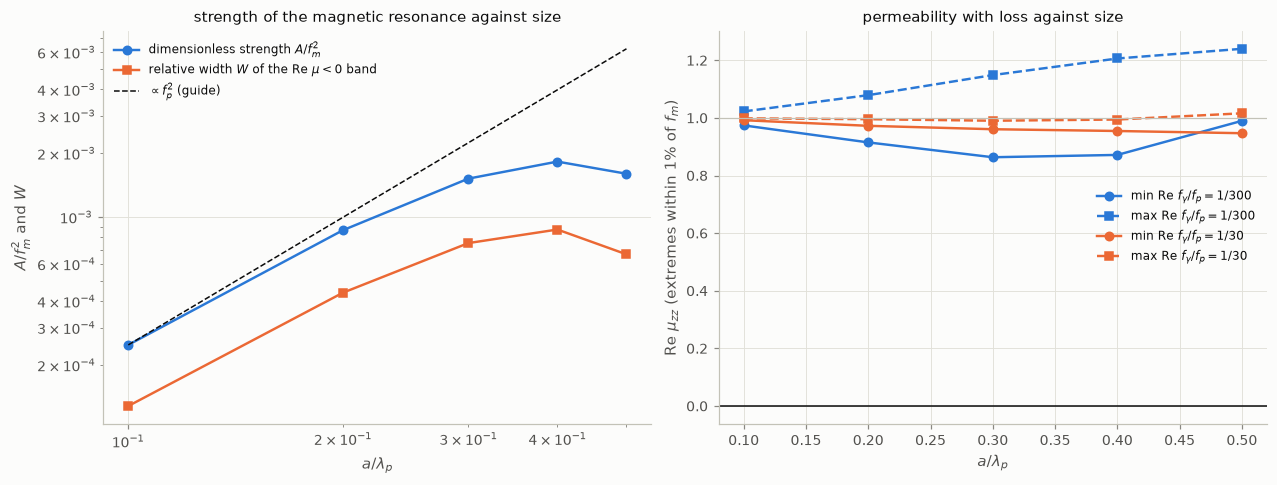

In [23]:
fps = np.array([r_["fp"] for r_ in SIZE])
Ares = np.array([r_["A"] for r_ in SIZE])
Wrel = np.array([r_["W"] for r_ in SIZE])
fm_s = np.array([r_["fm"] for r_ in SIZE])
base = SIZE[FP_LIST.index(FP)]
check("the size scan at f_p = 0.2 (3 Cauchy points per direction) gives the same pole of tau as section 2.2 (4 points; relative)", base["fm"] / F_M - 1, 1e-5)
check("... and the same pole of mu (relative to f_m - f_P)", (base["fm"] - base["fP"]) / (F_M - F_P) - 1, 2e-2)
slope = np.polyfit(np.log(fps[:4]), np.log(Ares[:4]), 1)[0]
print(f"residue A of the pole of k0^2 tau grows like f_p^{slope:.2f} between f_p = 0.1 and 0.4; between 0.4 and 0.5 it grows by a factor {Ares[4] / Ares[3]:.2f}")
# A has the dimension of f^2: k0^2 tau = A / (f_m^2 - f^2). The dimensionless strength is A / f_m^2
Astr = Ares / fm_s**2
slope_s = np.polyfit(np.log(fps[:4]), np.log(Astr[:4]), 1)[0]
loc_exp = np.diff(np.log(Astr)) / np.diff(np.log(fps))
print(f"A has the dimension of f^2, so a response of unchanged dimensionless strength would give A proportional to f_m^2, i.e. to f_p^2 (f_m/f_p is constant to 2 percent)")
print(f"dimensionless strength A/f_m^2: {np.round(Astr, 6).tolist()}; exponent against f_p from 0.1 to 0.4: {slope_s:.2f} (= {slope:.2f} minus about 2); local exponents {np.round(loc_exp, 2).tolist()} for 0.1-0.2, 0.2-0.3, 0.3-0.4, 0.4-0.5")
print(f"relative width W of the Re mu < 0 band: {np.round(Wrel, 6).tolist()} (saturates like A/f_m^2)")
gam_m = [(1 / 300) * r_["fp"] / r_["fm"] for r_ in SIZE]
print(f"loss against width: f_gamma/f_m = (1/300) f_p/f_m = {np.round(gam_m, 5).tolist()}; W / (f_gamma/f_m) = {np.round(Wrel / np.array(gam_m), 3).tolist()}")
assert (Wrel < np.array(gam_m)).all(), "with bulk-silver loss the negative band is wider than the loss at some size"
print(f"largest W over f_gamma/f_m = {(Wrel / np.array(gam_m)).max():.2f}: the size criterion for Re mu < 0 is W against f_gamma/f_m, and no size meets it")
assert loc_exp[3] < 0 < loc_exp[2] < loc_exp[1] < loc_exp[0] < 2.0
print(f"resonance frequency over f_p: {np.round(fm_s / fps, 4).tolist()}; relative width of the Re mu < 0 band: {np.round(Wrel, 6).tolist()}")
assert (np.diff(Ares) > 0).all() and slope > 3
check("the resonance frequency scales with f_p (f_m / f_p varies by less than 3 percent over f_p = 0.1 to 0.5; spread over the mean)", (fm_s / fps).max() / (fm_s / fps).min() - 1, 0.03)
for r_ in SIZE:
    assert r_[1 / 300]["n_neg"] == 0 and r_[1 / 30]["n_neg"] == 0
assert min(r_[1 / 300]["min_re"] for r_ in SIZE) > 0.85 and max(r_[1 / 300]["max_re"] for r_ in SIZE) < 1.26
assert 0.25 < max(r_[1 / 300]["max_im"] for r_ in SIZE) < 0.5
assert np.argmax(Wrel) == FP_LIST.index(0.4)
print("no size shows Re mu < 0 with f_gamma / f_p = 1/300 or 1/30 (the grid points inside 1% of the resonance)")
beyond = [r_["fp"] for r_ in SIZE if r_["fm"] > r_["f_bragg"]]
print(f"f_m exceeds the Bragg estimate 1/(2 sqrt(eps_T)) for f_p = {beyond}")

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.3))
axs[0].loglog(fps, Astr, "o-", color=CAT[0], label=r"dimensionless strength $A/f_m^2$")
axs[0].loglog(fps, Wrel, "s-", color=CAT[1], label=r"relative width $W$ of the Re $\mu<0$ band")
axs[0].loglog(fps, Astr[0] * (fps / fps[0]) ** 2, color=INK, ls="--", lw=1, label=r"$\propto f_p^2$ (guide)")
axs[0].set(xlabel=r"$a/\lambda_p$", ylabel=r"$A/f_m^2$ and $W$", title="strength of the magnetic resonance against size")
axs[0].legend(loc="upper left", fontsize=8)
for loss, c_, lab in ((1 / 300, CAT[0], r"$f_\gamma/f_p=1/300$"), (1 / 30, CAT[1], r"$f_\gamma/f_p=1/30$")):
    axs[1].plot(fps, [r_[loss]["min_re"] for r_ in SIZE], "o-", color=c_, label="min Re " + lab)
    axs[1].plot(fps, [r_[loss]["max_re"] for r_ in SIZE], "s--", color=c_, label="max Re " + lab)
axs[1].axhline(1.0, color=AXIS, lw=0.8); axs[1].axhline(0.0, color=INK, lw=1.0)
axs[1].set(xlabel=r"$a/\lambda_p$", ylabel=r"Re $\mu_{zz}$ (extremes within 1% of $f_m$)", title="permeability with loss against size")
axs[1].legend(loc="center right", fontsize=8)
plt.show()

**Other geometries.** The last cell varies the ring radius and the rod radius at $f_p=0.2$. For the moderate changes the residue $A$ changes by less than a factor of two and $\varepsilon_T$ stays below ten. For a ring of radius 0.30 the pole of $\tau$ found near the isolated-ring resonance has a large negative $\varepsilon_T$ (printed) and a residue more than three orders of magnitude larger. This is read, as a hypothesis, as a point where the magnetic and the electric responses of the lattice mix, not as the resonance of a permeability: $\varepsilon_T$ itself varies violently there, so a description by one permeability on a smooth $\varepsilon_T$ is not what the lattice shows. The exploration is five geometries at one $f_p$, not a search.

In [24]:
print("other geometries (f_p = 0.2): is the weak response a choice of s and r?")
print("    s      r    gap     f_m        W = (f_m - f_P)/f_m        A        eps_T(f_m (1 - 2e-3))")
t0 = time.perf_counter()
GEO = []
for s_, r_ in ((S_RING, R_ROD), (0.18, 0.08), (0.25, 0.08), (0.22, 0.10), (0.30, 0.08)):
    g_ = bl.check_rods(ring(-3.0, s_, r_))
    f_iso = isolated_peak(FP, s_, r_)
    try:
        fm_, fP_ = find_poles(f_iso, FP, s_, r_, span=0.012, n=13, ncau=3)
        fa = fm_ * (1 - 2e-3)
        ca = coefs(fa, 0.0, FP, s_, r_, n=3)
        A_ = (fm_**2 - fa**2) * (TWO_PI * fa) ** 2 * ca["tau"].real
        GEO.append((s_, r_, g_, fm_, (fm_ - fP_) / fm_, A_, ca["eps"].real))
        print(f"  {s_:5.2f} {r_:6.3f} {g_:6.3f} {fm_:9.5f} {(fm_ - fP_) / fm_:16.2e} {A_:17.3e} {ca['eps'].real:10.2f}")
    except Exception as ex:
        print(f"  {s_:5.2f} {r_:6.3f} {g_:6.3f}   no pole of tau found near the ring resonance ({type(ex).__name__})")
print(f"[{time.perf_counter() - t0:.0f} s]")
A_mod = [g_[5] for g_ in GEO if abs(g_[6]) < 10]
print(f"residue A over the geometries with a moderate eps_T: {min(A_mod):.2e} to {max(A_mod):.2e} (ratio {max(A_mod) / min(A_mod):.2f}); the largest ring: eps_T = {GEO[-1][6]:.0f} at its 'pole'")
assert len(A_mod) == 4 and max(A_mod) / min(A_mod) < 2.0
assert abs(GEO[-1][6]) > 50

other geometries (f_p = 0.2): is the weak response a choice of s and r?
    s      r    gap     f_m        W = (f_m - f_P)/f_m        A        eps_T(f_m (1 - 2e-3))


   0.22  0.080  0.151   0.12773         4.39e-04         1.411e-05       2.90


   0.18  0.080  0.095   0.11989         3.83e-04         1.071e-05       1.92


   0.25  0.080  0.194   0.13087         2.47e-04         1.162e-05       4.63


   0.22  0.100  0.111   0.11845         7.18e-04         1.977e-05       2.85


   0.30  0.080  0.240   0.13353         9.26e-03         5.184e-02    -164.37
[21 s]
residue A over the geometries with a moderate eps_T: 1.07e-05 to 1.98e-05 (ratio 1.85); the largest ring: eps_T = -164 at its 'pole'


In [25]:
# the numbers that the summary quotes, pinned to the computed values
print("headline numbers")
check("isolated ring: magnetic resonance (a/lambda_0)", f_mag_iso, 1e-5, 0.12770)
check("lattice: f_m, pole of tau (mu = 0)", F_M, 1e-5, 0.12773)
check("lattice: f_P, pole of mu", F_P, 1e-5, 0.12767)
check("lattice: width of the band with Re mu < 0, relative to f_m", (F_M - F_P) / F_M, 1e-5, 4.4e-4)
check("Landau-Lifshitz ratio 0.1 percent below the resonance (lossless, with lambda)", LL[-1e-3], 0.3, 11.8)
check("Landau-Lifshitz ratio 3 percent below the resonance (lossless, with lambda)", LL[-3e-2], 0.1, 1.4)
check("Landau-Lifshitz ratio with f_gamma/f_p = 1/300, printed maximum (with lambda)", LL_LOSS[1 / 300][0], 0.1, 4.44)
check("Landau-Lifshitz ratio with f_gamma/f_p = 1/30, printed maximum (with lambda)", LL_LOSS[1 / 30][0], 0.1, 1.57)
check("mu_X model within 1 percent of the exact wavenumber up to k a", k_1pct, 0.05, 1.5)
check("bulk-silver loss: smallest Re mu", SUM[1 / 300]["min_re"], 0.01, 0.915)
check("bulk-silver loss: largest Re mu", SUM[1 / 300]["max_re"], 0.01, 1.080)
check("bulk-silver loss: largest Im mu", SUM[1 / 300]["max_im"], 0.01, 0.170)
check("loss 1e-5 f_p: best figure of merit -Re mu / Im mu", SCAN[1e-5]["fom"], 1.0, 14.0)
check("loss 1e-4 f_p: best figure of merit", SCAN[1e-4]["fom"], 0.1, 1.2)
assert ANI[-3e-2] > 1.0 and abs(ANI[-1e-3]) < 0.1
check("exponent of the residue A against f_p (0.1 to 0.4; includes two powers that are units)", slope, 0.1, 3.46)
check("exponent of the dimensionless strength A / f_m^2 against f_p (0.1 to 0.4)", slope_s, 0.1, 1.48)

headline numbers
PASS  isolated ring: magnetic resonance (a/lambda_0): got 0.127701, target 0.1277, |diff| 5.94e-07 <= 1e-05
PASS  lattice: f_m, pole of tau (mu = 0): got 0.12773, target 0.12773, |diff| 2.01e-07 <= 1e-05
PASS  lattice: f_P, pole of mu: got 0.127674, target 0.12767, |diff| 4.17e-06 <= 1e-05
PASS  lattice: width of the band with Re mu < 0, relative to f_m: got 0.000438701, target 0.00044, |diff| 1.30e-06 <= 1e-05
PASS  Landau-Lifshitz ratio 0.1 percent below the resonance (lossless, with lambda): got 11.7648, target 11.8, |diff| 3.52e-02 <= 3e-01
PASS  Landau-Lifshitz ratio 3 percent below the resonance (lossless, with lambda): got 1.44649, target 1.4, |diff| 4.65e-02 <= 1e-01
PASS  Landau-Lifshitz ratio with f_gamma/f_p = 1/300, printed maximum (with lambda): got 4.43992, target 4.44, |diff| 7.56e-05 <= 1e-01
PASS  Landau-Lifshitz ratio with f_gamma/f_p = 1/30, printed maximum (with lambda): got 1.57413, target 1.57, |diff| 4.13e-03 <= 1e-01
PASS  mu_X model within 1 pe

## Summary

- **The isolated ring.** The $m=0$ coefficient of the cluster T-matrix has one resonance, below the electric ones and below the single-rod resonance $f_p/\sqrt2$; at the resonance it reaches the unitarity limit, and the cluster solution there is four equal tangential dipoles (radial components zero to rounding). A coupled-dipole model with each rod's polarizability taken from its Mie coefficient puts the resonance within about one percent of the T-matrix peak.
- **The lattice.** Bloch modes and the source-driven $\varepsilon(\omega,\mathbf k)$ agree: modes even under the mirror satisfy $k^2=k_0^2\varepsilon_T$ to $3\times10^{-11}$, odd modes do not, and the pole of $\tau$ equals the Bloch mode at small $k$ to $4\times10^{-9}$ in $a/\lambda_0$. The magnetic resonance of the lattice is at $a/\lambda_0=0.1277$, shifted from the isolated ring by $2\times10^{-4}$ (relative). $\tau$ has a pole there and $\mu$ is negative between the pole of $\mu$ and the pole of $\tau$, an interval that is $4\times10^{-4}$ of the frequency wide without loss.
- **Is it a permeability?** Without loss, and with $\lambda$ in the denominator, the pole term of $\tau$ is 1.4 times the largest of the other second-order terms at 3 percent below the resonance, 12 times at 0.1 percent below and over 100 times at 0.01 percent below; above the resonance it is below one at 1 percent. With loss the ratio, computed with the resonant part defined as the lossy $\tau$ minus the collisionless background, reaches the maximum printed in section 3 (4.4 for $f_\gamma/f_p=1/300$ and 1.6 for $1/30$ with $\lambda$ in the denominator; 15 and 2.3 without $\lambda$). The apparent permeabilities along $\Gamma X$ and $\Gamma M$ differ by more than $\mu-1$ itself at 3 percent below the resonance and by less than a tenth of it at 0.1 percent below. A local model with $\varepsilon_T$ and $\mu_X$ reproduces the exact Bloch wavenumber to one percent up to $ka\approx1.5$ and fails beyond, where the first band flattens (the cause was not tested).
- **Loss.** With $f_\gamma/f_p=1/300$ the real part of $\mu$ stays between 0.915 and 1.08 and its imaginary part reaches 0.17; with $1/30$ the resonance is almost gone. The negative band survives at $f_\gamma/f_p=2\times10^{-4}$ and is gone at $3\times10^{-4}$, a factor of 11 to 17 below the bulk-silver value, with a figure of merit of 14 at $10^{-5}$ and 1.2 at $10^{-4}$.
- **Size.** Making the structure electrically larger ($f_p=a/\lambda_p$ from 0.1 to 0.5) moves the resonance in proportion to $f_p$ and strengthens it, though less than the residue suggests: $A$ grows like $f_p^{3.5}$ between 0.1 and 0.4, of which two powers are units, and the dimensionless strength $A/f_m^2$ grows like $f_p^{1.5}$ over the same range and then saturates (printed exponents). With bulk-silver loss $\mathrm{Re}\,\mu$ stays between 0.86 and 1.24 over the whole range, and for $f_p=0.5$ the resonance lies beyond the first Bragg estimate of the lattice.
- **What this says about the claim of a strong optical permeability.** For this structure (two dimensions, four Drude rods per cell, $H$ along the rods, one ring per cell), the circulating mode does give a resonant $\tau$ and a negative $\mu$, and without loss the Landau-Lifshitz ratio of its resonant part exceeds 10 only within about a tenth of a percent of its pole (with $\lambda$ in the denominator); with loss the ratio is the printed maximum of section 3 (4.4 for $f_\gamma/f_p=1/300$ and 1.6 for $1/30$ with $\lambda$ in the denominator; 15 and 2.3 without $\lambda$). It is also weak: without loss the negative band is $4\times10^{-4}$ wide at the base structure (below $10^{-3}$ at every size computed), and with bulk-silver loss $\mu$ never reaches below 0.86, for sizes $f_p=0.1$ to 0.5 (the largest lies beyond the first Bragg estimate of the lattice). Nothing here says anything about three-dimensional particles, other geometries, or other metals.

## Caveats and open ends

- One structure, explored at five geometries (section 4). The residue $A$ changes by less than a factor of two for moderate changes of $s$ and $r$ and the relative width $W$ by almost a factor of three (printed); the larger ring puts the pole of $\tau$ where $\varepsilon_T$ is large and negative (printed), which was not analyzed. Rods of a different shape, a different number of rods per ring, several rings per cell, and the ring of three-dimensional particles of the original proposal were not computed.
- Two dimensions and TE only; the Drude model has no interband absorption, no nonlocal metal response and no surface scattering, and the loss values $1/300$ and $1/30$ are bulk-silver loss and ten times that. Published Drude fits for silver give $\lambda_p$ between 135 and 147 nm and $\gamma/\omega_p$ between about $1/440$ and $1/190$ (checked 2026-11-23; see the README), so $1/300$ is a typical bulk value. With $\lambda_p\approx138$ nm, $f_p=0.2$ means $a\approx28$ nm and rods of radius about 2 nm; size-dependent damping, $\gamma_{\rm bulk}+Av_F/r$ with $A$ of order one, adds about $0.05A\,\omega_p$ at that radius, several times the bulk value, so $1/30$ is the more realistic of the two values and the conclusions about weakness would be stronger, not weaker. Nothing in this notebook computes that damping.
- The checks of the Drude-rod lattice are internal: the Bloch modes against the driven response, the unitarity and symmetry of the T-matrix, the cluster solution against its boundary conditions. The plane-wave check could be carried out only for dielectric rods because the expansion with negative permittivity does not converge; the multiple-scattering solver is therefore not tested against a plane-wave solution for the metal.
- Extremes of $\mu$ with loss are values on a geometric grid in the detuning and are indicative at the level of a few percent at best. The Cauchy integrals use three or four samples per half circle (aliasing errors of $10^{-8}$ to $10^{-6}$ in the pole position, printed) and a circle radius of 0.03, which was tested for independence at three detunings from the pole (section 2.2). A circle of radius 0.15 gives an error of about half a percent in $\tau$ at a detuning of $10^{-5}$ (printed in 2.2), because the radius of convergence in $\kappa$ shrinks with the detuning; the sections that use the default radius are not affected.
- The Landau-Lifshitz ratio rests on a pole-plus-smooth fit and is a model split; it was not separated term by term in the microscopic problem.
- The second-order model does not describe the upper band just above $f_m$ (the printed fraction of the distance above $f_m$ in section 3), and was compared with the Bloch modes only on the first band. The mode condition and the model were tested without loss. With loss only reciprocity and the sign of $\mathrm{Im}\,\varepsilon_T$ were checked.
- $f_p=0.5$ puts $f_m$ above the Bragg estimate of the lattice; the numbers are printed and not interpreted.
- Not done: the reflection of a slab of rings (the retrieval problem of notebook 04 for this structure), where the magnetic response and the weakness found here would meet the termination effects found there.

## References

- A. Alù, A. Salandrino, N. Engheta, "Negative effective permeability and left-handed materials at optical frequencies", Opt. Express 14, 1557 (2006) (checked 2026-11-23).
- A. Alù and N. Engheta, "Dynamical theory of artificial optical magnetism produced by rings of plasmonic nanoparticles", Phys. Rev. B 78, 085112 (2008) (checked 2026-11-23).
- M. G. Silveirinha, Phys. Rev. B 75, 115104 (2007), source-driven homogenization.
- L. D. Landau, E. M. Lifshitz and L. P. Pitaevskii, *Electrodynamics of Continuous Media*, 2nd ed., sections 79 and 103.
- R. Merlin, Proc. Natl. Acad. Sci. USA 106, 1693 (2009).
- J. Skaar, H. O. Hågenvik and C. A. Dirdal, Phys. Rev. B 99, 064407 (2019).

In [26]:
print(f"total run time {time.perf_counter() - T0:.0f} s")

total run time 192 s
